# 4-estimators: winding-temperature

Estimate the winding's temperature from the board NTC and the copper loss, one step at a time the way a loop has to, and grade the estimate where stage 3's sittings already hold the winding's own resistance. No thermal sitting ran, in stage 3 or for this notebook. The thermometer is the winding itself. With the rotor stopped there is no back-EMF, so the terminal volts over the current give the winding's resistance, and copper's resistance rises with its temperature at a known rate.

The data grades the first 3 s of a drive from a rested winding. Stage 3's holds are short, each drive follows a rest, and no sitting held the winding warm. A thermal derate or a cutoff built on this estimate has no graded basis past those 3 s.

## Purpose

- The reads. Every stopped-rotor resistance read in stage 3's sittings, gated for a still and quiet rotor, with where it sits, the thermometer's floor at one seat and across seats, and the commutator seats that read low.
- The heat history. The copper loss against time over every stage 3 sweep, the share no row streamed, and the bounds on that share.
- The estimate. The NTC plus heat nodes driven by the copper loss, fitted on some sittings and scored on the others, against the NTC alone. What bounds the time constant, what the data says about a second node, and the swap of the two halves.
- The speed cost. What an error in R costs the back-EMF speed at the load holds' currents, with the NTC alone and with one node.
- The verdict. What stage 3's sittings grade and what they do not, each gap with the capture that would close it, and the bound a loop designer carries meanwhile.
- What stages 5 and 6 read. The form, the constants with their brackets, the error where graded, where it is not graded, the start-up assumption and the hazards of a live stopped-rotor read.

## Procedure

No sitting ran for this notebook. The estimate is a pure function in `oscnb.winding`, run down the heat history in time order from a zero state, every candidate causal. The truth it is graded against is the stopped-rotor read, offline. The README's rules of the desk hold here. An estimator is causal, the arithmetic is float, a grade is held out with its split named, constants come through the chain, and a threshold comes from the servo's own noise or constants.

The method follows an analysis note that was reviewed and reproduced before this notebook was written. Every number is mg90-d's, from mg90-d's own data.

## Data

Everything is under `telemetry/mg90-d__dev-v006-2A-D/`, four days of stage 3 sittings.

- `resistance/`, the locked horn's laps `locked-4`, the end-stop chains `stop-1` and `rails-7`, and the meter holds `meter-8` with the DMM in series.
- `sag/`, the stop laps of `capture-1` and the long hold `held-5` on the horn lock.
- `load/`, the arm's ladders, duty steps and bottom rests, three blocks of each.
- Every other stage 3 sweep for the heat history, the free ladders, steps, run-ups and the pot-table sitting among them.
- `sittings/`, one manifest per sitting with a torque-off probe of the board NTC before every sweep.

Each sweep folder holds `sweep.csv`, one row per control tick, `segments.csv` with each segment's host start and end and whether it was streamed, and `meta.json`, whose sense block is checked against the board's registry entry on load.

The libraries, then the pair and its folders.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.optimize import least_squares

from oscnb import boards, figures, results, scales, servos, speed
from oscnb import winding as wd
from oscnb.figures import BLUE, GREEN, INK, MUTED, ORANGE, RED

pd.set_option("display.width", 200)    # the printed tables run wide

In [2]:
SERVO = servos.SERVOS["mg90-d"]         # the servo: pot, train, limits
BOARD = boards.BOARDS[boards.DEFAULT]   # the board, checked on every sweep
PAIR = f"{SERVO.key}__{BOARD.key}"      # the pair, the result file's name
PAIR_DIR = (Path("../../../telemetry") / PAIR).resolve()
STAGE, EXPERIMENT = "4-estimators", "winding-temperature"
print(SERVO.key, "on", BOARD.key, "from", results.rel(PAIR_DIR))
print(f"control tick {BOARD.tick_hz} rows/s, {BOARD.pwm_arr} ticks at 100 %")

mg90-d on dev-v006-2A-D from telemetry/mg90-d__dev-v006-2A-D
control tick 20000 rows/s, 1200 ticks at 100 %


## 1. The rig, the data and the constants

### The constants, through the chain

Stage 1's scales give the current channel, the taps and the edge lags, and the in-drive offset the reads take as their zero, the zero stage 3's resistance and load notebooks read with. Stage 3's resistance result gives the reference resistance R0 at the board NTC T0 of the locked laps, the brush drop V0, the reading term's g and the quiet gate, its inductance result the brake line, its ladder result Ke, and its pot-table result the pot's scale. `oscnb.speed.chain_of` and `motor_of` bind them. Copper's slope is the only typed number, a physical constant.

In [3]:
SC = scales.load(BOARD)                 # stage 1's conversions of the board
RES = results.read("3-servo", "resistance", pair=PAIR)
IND = results.read("3-servo", "inductance", pair=PAIR)
LAD = results.read("3-servo", "ladder", pair=PAIR)
POT = results.read("3-servo", "pot-table", pair=PAIR)
LOAD3 = results.read("3-servo", "load", pair=PAIR)
CHAIN = speed.chain_of(BOARD, SC)       # the sense chain, from the scales
MOTOR = speed.motor_of(RES, IND, LAD)   # R0, T0, V0, g, brake line, Ke
ZERO = SC.drive_offset_counts           # counts, the reads' in-drive zero
QUIET_SD = wd.quiet_sd_of(RES)          # counts, stage 3's quiet gate
POT_SCALE = POT["pot_scale_counts_per_deg"]["value"]  # counts/output deg
GEAR = SERVO.gear_ratio                 # motor turns per output turn
R0, T0 = MOTOR.r_ohm, MOTOR.t0_c        # the reference, ohm at C
ALPHA = MOTOR.alpha_per_c               # per C, copper's slope
C_PER_PCT = 0.01 / ALPHA                # C per 1 % of R
r0q = RES["r_rails_at_measured_e_ohm"]  # the reference with its bracket
v0q = RES["v0_rails_at_measured_e_v"]   # V0 with its bracket
print(f"R0 {R0:.4f} ohm ({r0q['lo']:.4f} to {r0q['hi']:.4f}) at T0 "
      f"{T0:.2f} C")
print(f"V0 {MOTOR.v0_v * 1e3:+.1f} mV ({v0q['lo'] * 1e3:+.1f} to "
      f"{v0q['hi'] * 1e3:+.1f})")
print(f"g {MOTOR.g_s * 1e3:.3f} mS, brake line {MOTOR.brake_b0_v * 1e3:.1f}"
      f" mV + {MOTOR.brake_b1_ohm:.3f} ohm x i, Ke "
      f"{MOTOR.ke_v_per_rev_s * 1e3:.4f} mV per rev/s")
print(f"zero {ZERO:.3f} counts over the asleep zero, "
      f"{1 / CHAIN.a_per_count:.2f} counts/A, quiet gate sd <= "
      f"{QUIET_SD:.2f} counts")
print(f"pot {POT_SCALE:.3f} counts/deg, gear {GEAR:.2f}:1")
print(f"copper {100 * ALPHA:.2f} %/C, 1 % of R = {C_PER_PCT:.2f} C")

R0 4.1767 ohm (4.1676 to 4.1932) at T0 26.26 C
V0 +33.2 mV (+16.3 to +40.4)
g 4.746 mS, brake line 8.7 mV + 0.240 ohm x i, Ke 7.2828 mV per rev/s
zero 5.261 counts over the asleep zero, 1135.01 counts/A, quiet gate sd <= 8.98 counts
pot 18.913 counts/deg, gear 308.05:1
copper 0.39 %/C, 1 % of R = 2.56 C


In [4]:
SOURCES = pd.DataFrame([           # every constant with its result key
    ("R0", "3-servo resistance", "r_rails_at_measured_e_ohm"),
    ("T0", "3-servo resistance", "board_ntc_c"),
    ("V0", "3-servo resistance", "v0_rails_at_measured_e_v"),
    ("g", "3-servo resistance", "meter_g_ms"),
    ("quiet gate", "3-servo resistance", "quiet_gate_i_sd_counts (hi)"),
    ("brake line", "3-servo inductance", "brake_line_motor_plain"),
    ("Ke", "3-servo ladder", "ke_mv_per_rev_s"),
    ("pot scale", "3-servo pot-table", "pot_scale_counts_per_deg"),
    ("zero, counts/A", "1-board current-scale", "drive_offset_counts"),
    ("taps, edge lags", "1-board terminal-chain, sample-timing", "-"),
    ("gear ratio", "oscnb.servos", "mg90-d gear_ratio"),
    ("copper", "typed, physical", "0.39 %/C"),
], columns=["constant", "result", "key"])
print(SOURCES.to_string(index=False))

       constant                                result                         key
             R0                    3-servo resistance   r_rails_at_measured_e_ohm
             T0                    3-servo resistance                 board_ntc_c
             V0                    3-servo resistance    v0_rails_at_measured_e_v
              g                    3-servo resistance                  meter_g_ms
     quiet gate                    3-servo resistance quiet_gate_i_sd_counts (hi)
     brake line                    3-servo inductance      brake_line_motor_plain
             Ke                        3-servo ladder             ke_mv_per_rev_s
      pot scale                     3-servo pot-table    pot_scale_counts_per_deg
 zero, counts/A                 1-board current-scale         drive_offset_counts
taps, edge lags 1-board terminal-chain, sample-timing                           -
     gear ratio                          oscnb.servos           mg90-d gear_ratio
         copper 

Stage 3's own thermal readings, quoted for the comparisons in sections 4 and 7. None of them enters the estimate.

In [5]:
def val(d, key):
    """A result quantity's value."""
    return d[key]["value"]


S3_C_MAX = val(RES, "copper_heat_capacity_max_j_per_c")  # J/C, 3.7 V laps
S3_LAP_PCT_J = val(RES, "warming_pct_per_j")         # %/J, 3.7 V laps
S3_LAP_PCT_J_3V3 = val(RES, "warming_pct_per_j_3v3")  # %/J, 3.3 V laps
S3_METER_TAU = RES["meter_heating_tau_s"]            # s, one exponential
S3_R0_CUBIC = LOAD3["r0_cubic_ohm"]                  # ohm, load intercept
S3_HOLD_PCT = LOAD3["hold_warming_pct_at_0p5a_3s"]   # %, 0.5 A for 3 s
print(f"stage 3: copper heat capacity at most {S3_C_MAX:.3f} J/C, laps "
      f"{S3_LAP_PCT_J:.2f} %/J (3.7 V), {S3_LAP_PCT_J_3V3:.2f} %/J (3.3 V)")
print(f"stage 3: meter hold tau {S3_METER_TAU['value']:.2f} s "
      f"({S3_METER_TAU['lo']:.2f} to {S3_METER_TAU['hi']:.2f})")
print(f"stage 3: load intercept {S3_R0_CUBIC['value']:.2f} ohm "
      f"({S3_R0_CUBIC['lo']:.2f} to {S3_R0_CUBIC['hi']:.2f}), "
      f"{100 * (S3_R0_CUBIC['value'] / R0 - 1):+.1f} % of R0")
print(f"stage 3: hold warming at 0.5 A for 3 s {S3_HOLD_PCT['value']:.2f} "
      f"% (low {S3_HOLD_PCT['lo']:.2f})")

stage 3: copper heat capacity at most 0.077 J/C, laps 4.96 %/J (3.7 V), 3.11 %/J (3.3 V)
stage 3: meter hold tau 3.39 s (3.08 to 3.74)
stage 3: load intercept 4.11 ohm (4.07 to 4.15), -1.6 % of R0
stage 3: hold warming at 0.5 A for 3 s 9.99 % (low 4.82)


## 2. The reads

### The board NTC

The rows carry no NTC. `ntc_raw` is empty in every sweep, like `vbus`. The board NTC comes from the sitting manifests instead, which hold a torque-off probe before every sweep. `oscnb.winding.probes` reads them through the board's beta curve and `ntc_at` draws a line through them in time. The NTC sits on the board, outside the servo's case, so it reads the board and the room, not the can.

In [6]:
IX = wd.index(PAIR_DIR)                 # every sweep in time, its sitting
PROBES = wd.probes(PAIR_DIR, BOARD, SC)  # the torque-off NTC probes
raw = float(PROBES["ntc_raw"].median())  # a typical NTC reading, counts
step_c = np.diff(BOARD.ntc_c_beta(np.array([raw, raw + 1.0])))[0]
NTC_PER_COUNT = abs(float(step_c))      # C per count of the NTC
NTC_SPAN = (PROBES["ntc_c"].min(), PROBES["ntc_c"].max())
days = pd.to_datetime(IX["t_start"], unit="s").dt.strftime("%m-%d")
print(f"{len(IX)} sweeps in {IX['sitting'].max()} sittings, days "
      f"{', '.join(sorted(days.unique()))}")
print(f"{len(PROBES)} probes over {PROBES['manifest'].nunique()} "
      f"manifests, NTC {NTC_SPAN[0]:.1f} to {NTC_SPAN[1]:.1f} C, one "
      f"count {NTC_PER_COUNT:.3f} C")

521 sweeps in 10 sittings, days 11-06, 11-07, 11-08, 11-09
567 probes over 11 manifests, NTC 24.5 to 28.7 C, one count 0.022 C


In [7]:
by = PROBES.groupby("manifest")
NTC_SIT = pd.DataFrame({
    "probes": by.size(),
    "minutes": (by["t"].max() - by["t"].min()) / 60,
    "first_c": by["ntc_c"].first(),     # at the sitting's first probe
    "low_c": by["ntc_c"].min(),
    "high_c": by["ntc_c"].max(),
    "last_c": by["ntc_c"].last(),
})
NTC_SIT["climb_c"] = NTC_SIT["high_c"] - NTC_SIT["first_c"]
LONG_SIT = NTC_SIT[NTC_SIT["minutes"] >= 15]    # sittings of 15 min or more
print(NTC_SIT.round(2).to_string())
print(f"climb from the first probe, sittings of 15 min or more: "
      f"{LONG_SIT['climb_c'].min():.2f} to {LONG_SIT['climb_c'].max():.2f}"
      f" C")

                 probes  minutes  first_c  low_c  high_c  last_c  climb_c
manifest                                                                 
servo-1             193   240.34    25.73  24.54   26.48   25.02     0.75
servo-4              27     7.78    26.01  26.01   26.44   26.35     0.42
servo-5              14     2.40    25.26  25.22   26.15   26.15     0.88
servo-6              24    16.67    25.64  25.64   26.70   26.70     1.06
servo-7              25    26.42    25.33  25.33   27.51   27.33     2.18
servo-camera-10       2     1.29    24.69  24.69   25.02   25.02     0.33
servo-camera-9       22    16.24    28.36  28.36   28.66   28.66     0.29
servo-load-1         76    63.30    26.26  26.24   27.13   27.08     0.87
servo-load-2         70    56.11    26.77  26.77   28.00   27.66     1.23
servo-load-3         79    66.20    26.99  26.99   28.32   28.32     1.32
servo-meter-8        35    29.12    26.24  26.24   28.11   28.11     1.88
climb from the first probe, sittings o

The probes span 24.5 to 28.7 C over the four days, one count of the NTC being 0.022 C. Inside a sitting the NTC climbs on its own after power-up, 0.29 to 2.18 C from the first probe over the sittings of 15 minutes or more. servo-7 runs from 25.33 to 27.51 C over 26.4 minutes and servo-meter-8 from 26.24 to 28.11 C over 29.1 minutes. The motor's mean power in those sittings is a few tens of milliwatts at most (section 3), so the climb is the board warming itself, not the winding. servo-1 is the exception, 240 minutes long, where the NTC ends at 25.02 C, under its first probe of 25.73 C.

In [8]:
print(f"sub-window {wd.SUB_ROWS} rows = "
      f"{wd.SUB_ROWS / CHAIN.fs_hz * 1e3:.0f} ms; gate: pot range <= "
      f"{wd.POS_RANGE_MAX} counts, current sd <= {QUIET_SD:.2f} counts, "
      f"{wd.SETTLE_S * 1e3:.0f} ms past a fresh duty, pot within "
      f"{wd.CREEP_MAX:g} counts of the segment's last sub-window")

sub-window 400 rows = 20 ms; gate: pot range <= 8 counts, current sd <= 8.98 counts, 60 ms past a fresh duty, pot within 2 counts of the segment's last sub-window


### The read

With the rotor stopped the back-EMF is zero, and the winding's resistance is

$$R = \frac{V_c - V_0}{i_w}$$

where $i_w$ is the winding current and $V_c$ the volts across the winding, both from `oscnb.speed.construct`, the construction stage 3's resistance and load notebooks read with, with stage 1's in-drive offset as the zero. $V_0$ is stage 3's brush drop. The copper temperature it implies is

$$T = T_0 + \frac{R / R_0 - 1}{\alpha}$$

with $\alpha$ (alpha) copper's slope of 0.39 %/C.

A read is a 20 ms sub-window, 400 rows, of a streamed driven segment of a stopped-rotor sweep that passes the gate in `oscnb.winding.gate`. The gate asks for

- the pot's range within the sub-window at most 8 counts, the locked-rotor gate,
- the current's sd at most stage 3's quiet gate,
- the window valid on every row, one duty and no dropout row,
- past 60 ms of a fresh duty, the seat's wind-up, where stage 3's laps start too,
- the pot within 2 counts of the segment's last sub-window, so the seat has stopped creeping.

The stopped-rotor sweeps are the resistance sittings, the sag's stop laps and its long hold, and every load block.

In [9]:
STOPPED = [          # (experiment, dataset) or with a folder suffix
    ("resistance", "locked-4"), ("resistance", "stop-1"),
    ("resistance", "rails-7"), ("resistance", "meter-8"),
    ("sag", "capture-1", "/stop"),      # the stop laps of the sag only
    ("sag", "held-5"),
    ("load", "bottom-1"), ("load", "ladder-1"), ("load", "steps-1"),
    ("load", "bottom-2"), ("load", "ladder-2"), ("load", "steps-2"),
    ("load", "bottom-3"), ("load", "ladder-3"), ("load", "steps-3"),
]
STOP_IX = wd.stopped_sweeps(IX, STOPPED)    # their rows of the index
SUB = wd.sub_windows(PAIR_DIR, STOP_IX, BOARD, CHAIN, MOTOR, ZERO,
                     PROBES)            # every 20 ms sub-window
OK = wd.gate(SUB, QUIET_SD)             # the reads among them
READS = wd.read_table(SUB, OK)          # one row per streamed window
print(f"{len(STOP_IX)} stopped-rotor sweeps, {len(SUB)} sub-windows of "
      f"{wd.SUB_ROWS} rows ({wd.SUB_ROWS / CHAIN.fs_hz * 1e3:.0f} ms)")
print(f"{int(OK.sum())} reads in {len(READS)} streamed windows of "
      f"{READS['folder'].nunique()} sweeps")

258 stopped-rotor sweeps, 7699 sub-windows of 400 rows (20 ms)
4476 reads in 426 streamed windows of 246 sweeps


In [10]:
keys = ["experiment", "dataset"]
counts = SUB.assign(gate=OK).groupby(keys, sort=False).agg(
    sitting=("sitting", "first"), sweeps=("folder", "nunique"),
    sub=("gate", "size"), gated=("gate", "sum"))
spread = READS.groupby(keys, sort=False).agg(
    windows=("r_ohm", "size"), i_lo=("i_w_a", "min"),
    i_hi=("i_w_a", "max"), r_lo=("r_ohm", "min"),
    r_med=("r_ohm", "median"), r_hi=("r_ohm", "max"),
    rail_lo=("rail_v", "min"), rail_hi=("rail_v", "max"),
    ntc=("ntc_c", "mean"))
BY_DATASET = counts.join(spread)
print(BY_DATASET.round(3).to_string())

                      sitting  sweeps   sub  gated  windows   i_lo   i_hi   r_lo  r_med   r_hi  rail_lo  rail_hi     ntc
experiment dataset                                                                                                      
resistance locked-4         2       6   169    133       12  0.728  0.757  4.229  4.306  4.347    3.451    3.504  26.232
           stop-1           1       6   270    186       18  0.241  0.371  4.148  4.185  4.200    4.798    4.842  26.019
           rails-7          5      12   540    431       36  0.231  0.374  4.100  4.167  4.233    3.512    7.233  26.858
           meter-8          6      34  1020    832       68  0.224  0.365  4.236  4.325  4.460    3.513    7.237  27.274
sag        capture-1        1      13   195    156       13  0.299  0.310  4.108  4.138  4.180    5.777    8.187  25.592
           held-5           3       1     9      6        2  0.150  0.196  4.113  4.157  4.201    6.463    8.232  25.803
load       bottom-1         9   

| sitting | dataset | sweeps | windows with a read | current A | how the read sits |
|---|---|---|---|---|---|
| 1 | resistance/stop-1 | 6 | 18 | 0.241 to 0.371 | end stops, after a seek press |
| 1 | sag/capture-1 stop laps | 13 | 13 | 0.299 to 0.310 | low stop, one lap per rail, after a seek press |
| 2 | resistance/locked-4 | 6 | 12 | 0.728 to 0.757 | horn lock, no seek, the one rested read with nothing constructed |
| 3 | sag/held-5 | 1 | 2 | 0.150 to 0.196 | horn lock, either side of one long hold, the rail stepped down inside it |
| 5 | resistance/rails-7 | 12 | 36 | 0.231 to 0.374 | end stops, two rails, after a seek press |
| 6 | resistance/meter-8 | 34 | 68 | 0.224 to 0.365 | end stops, three rails, the DMM in series |
| 9, 10 | load/ladder-1 to 3 | 45, 35, 32 | 54, 86, 38 | 0.050 to 0.515 | the arm held against gravity |
| 9, 10 | load/steps-1 to 3 | 12, 15, 28 | 24, 21, 39 | 0.050 to 0.550 | the arm held, a duty step at one seat |
| 9, 10 | load/bottom-1 to 3 | 6, 6, 6 | 6, 4, 5 | 0.115 to 0.203 | the arm at its bottom rest |

The load ladder's first streamed window of a hold is mostly not a read. The arm is still lifting through it, so the pot moves and the current falls with the back-EMF, and the gate keeps few of its sub-windows.

In [11]:
lad = SUB[SUB["dataset"].str.startswith("ladder")]
first_win = lad["seg"] == lad.groupby("folder")["seg"].transform("min")
print(f"ladder sub-windows: pot range median "
      f"{lad.loc[first_win, 'pos_range'].median():.0f} counts per 20 ms "
      f"in a hold's first window, "
      f"{lad.loc[~first_win, 'pos_range'].median():.0f} in the later ones")
print(f"reads in the first windows: {int(OK[lad.index[first_win]].sum())}"
      f" of {int(first_win.sum())} sub-windows")

ladder sub-windows: pot range median 18 counts per 20 ms in a hold's first window, 5 in the later ones
reads in the first windows: 19 of 459 sub-windows


In a hold's first window the pot moves a median 18 counts per 20 ms sub-window, against 5 in the windows after, and 19 of its 459 sub-windows pass the gate. A ladder hold gives one read, at its end. Two windows at one duty and one seat exist only in meter-8 and in the load's rungs taken from above.

### The blocks

The fits and the grade work on 100 ms blocks, the gated sub-windows of a window pooled by their time into the segment. A temperature is read only at a current floor, under which half of V0's bracket is over 2 % of R. A block well under R0 is a bridged commutator seat, below.

In [12]:
I_FLOOR = 0.14      # A, under it V0's half-bracket is over 2 % of R
BRIDGED = 0.90      # of R0, a block under it is a bridged seat
G = SUB[OK].copy()                      # the gated sub-windows
G["block"] = (G["t_in_seg"] // 0.1).astype(int)     # 100 ms blocks
BLK = G.groupby(["folder", "seg", "block"], sort=False).agg(
    experiment=("experiment", "first"), dataset=("dataset", "first"),
    sitting=("sitting", "first"), dir=("dir", "first"),
    fresh=("fresh", "first"), n_sub=("r_ohm", "size"), t=("t", "mean"),
    duty_pct=("duty_pct", "first"), rail_v=("rail_v", "mean"),
    i_w_a=("i_w_a", "mean"), v_c_v=("v_c_v", "mean"),
    pos=("pos", "mean"), ntc_c=("ntc_c", "mean"),
    r_ohm=("r_ohm", "mean")).reset_index()
over = BLK[BLK["i_w_a"] >= I_FLOOR]     # blocks at the current floor
KEPT = over[over["r_ohm"] >= BRIDGED * R0].copy()   # bridged seats out
V0_HALF = (v0q["hi"] - v0q["lo"]) / 2   # V, half of V0's bracket
print(f"{len(BLK)} blocks, {len(over)} at {I_FLOOR} A or more, "
      f"{len(over) - len(KEPT)} under {BRIDGED} of R0 (bridged), "
      f"{len(KEPT)} kept")
for i in (I_FLOOR, 0.3, 0.5):
    print(f"V0's half-bracket {V0_HALF * 1e3:.1f} mV at {i} A: "
          f"{100 * V0_HALF / (i * R0):.1f} % of R")

1116 blocks, 972 at 0.14 A or more, 12 under 0.9 of R0 (bridged), 960 kept
V0's half-bracket 12.0 mV at 0.14 A: 2.1 % of R
V0's half-bracket 12.0 mV at 0.3 A: 1.0 % of R
V0's half-bracket 12.0 mV at 0.5 A: 0.6 % of R


In [13]:
KEPT["dT_c"] = wd.dtemp_of_r(KEPT["r_ohm"], R0, ALPHA)  # over (R0, T0)
dT = KEPT["dT_c"]
RISE = {"lo": dT.min(), "hi": dT.max(), "median": dT.median(),
        "p05": dT.quantile(0.05), "p95": dT.quantile(0.95)}
print(f"implied rise over (R0, T0), {len(KEPT)} blocks: "
      f"{RISE['lo']:+.1f} to {RISE['hi']:+.1f} C, 5 to 95 %: "
      f"{RISE['p05']:+.1f} to {RISE['p95']:+.1f}")
print(KEPT.groupby("dataset", sort=False)["dT_c"].agg(
    ["size", "min", "max"]).round(1).T.to_string())
top = KEPT[KEPT["dataset"].str.startswith("ladder")
           & (KEPT["i_w_a"] >= 0.44)]   # the ladder's top rungs
print(f"ladder blocks at 0.44 A or more: {len(top)}, "
      f"{top['i_w_a'].min():.3f} to {top['i_w_a'].max():.3f} A, "
      f"{top['dT_c'].min():+.1f} to {top['dT_c'].max():+.1f} C")

implied rise over (R0, T0), 960 blocks: -6.0 to +25.3 C, 5 to 95 %: -3.4 to +13.4
dataset  locked-4  stop-1  rails-7  meter-8  capture-1  held-5  ladder-1  steps-1  bottom-2  ladder-2  steps-2  bottom-3  ladder-3  steps-3
size         36.0    53.0    108.0    201.0       39.0     2.0      39.0     72.0       8.0     138.0     80.0      10.0      21.0    153.0
min           1.0    -2.0     -5.0      3.6       -4.3    -3.9      -5.2     -5.6      -5.1      -3.9     -6.0      -2.4      -4.6     -4.2
max          11.9     1.5      3.6     17.5        0.3     1.5      25.3     13.9      -1.2      13.5      8.3      17.2       8.6     11.7
ladder blocks at 0.44 A or more: 14, 0.443 to 0.515 A, +6.3 to +25.3 C


In [14]:
inside = wd.SUB_ROWS / CHAIN.fs_hz      # s, sub-windows inside a window
within = IX.loc[IX["gap_s"] <= wd.SITTING_GAP_S, "gap_s"]  # sweep to sweep
sit = IX.groupby("sitting")
rests_h = (sit["t_start"].min().to_numpy()[1:]
           - sit["t_end"].max().to_numpy()[:-1]) / 3600
print(f"inside a window: one sub-window every {inside * 1e3:.0f} ms")
print(f"between sweeps of a sitting: median {within.median():.1f} s, "
      f"middle half {within.quantile(0.25):.1f} to "
      f"{within.quantile(0.75):.1f} s, n {len(within)}")
print(f"between sittings (a rest over {wd.SITTING_GAP_S} s), h: "
      + ", ".join(f"{h:.1f}" for h in rests_h))

inside a window: one sub-window every 20 ms
between sweeps of a sitting: median 47.5 s, middle half 44.6 to 48.4 s, n 511
between sittings (a rest over 600 s), h: 38.6, 0.2, 0.3, 2.0, 2.7, 20.1, 17.3, 1.1, 0.9


The blocks at the floor imply a rise over (R0, T0) of -6.0 to +25.3 C, 5 to 95 % of them -3.4 to +13.4 C. The largest are the load ladder's top rungs (14 blocks at 0.443 to 0.515 A, +6.3 to +25.3 C), meter-8 (+3.6 to +17.5 C, which includes the meter's burden in series, so its absolute level is not the winding's), the rest of the load (up to +17.2 C on bottom-3, +13.9 C on steps-1, +13.5 C on ladder-2) and the locked laps (+1.0 to +11.9 C). The stop chains, the sag's stop laps and held-5 sit within -5.0 to +3.6 C. A level read across seats carries the floor below, so only the same-seat ratios are graded as temperatures.

Reads come every 20 ms inside a streamed window. Sweeps follow each other a median 47.5 s apart, the middle half 44.6 to 48.4 s. The rests between sittings, a sitting being a run of sweeps with no rest over 600 s, run from 0.2 to 38.6 hours. The spacing of the reads inside a drive is in section 4, where the drives are cut from the heat history.

### The reference

R0 and T0 are stage 3's pair, read under the same construction on the end-stop chains. The coldest rested reads in the data are the locked laps of sitting 2. The servo was unpowered for hours before, the horn lock needs no seek, and at 100 % duty nothing switches, so nothing is constructed. Their read at the first driven row is the line through each lap's sub-windows taken back to the lap's start. The 3.3 V laps sit off stage 1's graded lines and are reported only, as stage 3 has them.

In [15]:
def line_at(g, t_at, col):
    """col's least-squares line in time through the rows of g, at t_at;
    the nearest row's value when g has under 3 rows."""
    t = g["t"].to_numpy() - t_at
    y = g[col].to_numpy()
    if len(g) >= 3:
        return float(np.polyval(np.polyfit(t, y, 1), 0.0))
    return float(y[np.argmin(np.abs(t))])


rows = []
for (folder, seg), g in G[G["dataset"] == "locked-4"].groupby(
        ["folder", "seg"], sort=False):
    t_first = g["t"].iloc[0] - g["t_in_seg"].iloc[0]   # the first row
    slope = np.polyfit(g["t"] - g["t"].mean(), g["r_ohm"], 1)[0]
    rows.append({"k": int(folder.split("/")[-1]), "seg": seg,
                 "dir": g["dir"].iloc[0], "rail": g["rail_v"].mean(),
                 "i": line_at(g, t_first, "i_w_a"),
                 "r_first_row": line_at(g, t_first, "r_ohm"),
                 "ntc": g["ntc_c"].mean(),
                 "slope_pct_s": slope / g["r_ohm"].mean() * 100,
                 "p_w": (g["i_w_a"] ** 2 * g["r_ohm"]).mean()})
LAPS = pd.DataFrame(rows)
LAPS["pct_per_j"] = LAPS["slope_pct_s"] / LAPS["p_w"]   # %/s per W
print(LAPS.round(4).to_string(index=False))

 k  seg  dir   rail      i  r_first_row     ntc  slope_pct_s    p_w  pct_per_j
 0    1    1 3.4547 0.7407       4.2765 26.1035       7.4353 2.3198     3.2052
 0    2   -1 3.4507 0.7375       4.2857 26.1144       7.0290 2.3061     3.0480
 1    1    1 3.4547 0.7388       4.2882 26.1925       7.0235 2.3157     3.0330
 1    2   -1 3.4507 0.7358       4.2956 26.2143       6.4472 2.3032     2.7992
 2    1    1 3.4547 0.7385       4.2900 26.2147       7.3070 2.3129     3.1592
 2    2   -1 3.4507 0.7365       4.2916 26.2365       7.0347 2.3032     3.0543
 3    1    1 3.5001 0.7657       4.1895 26.2376       9.5308 2.4234     3.9328
 3    2   -1 3.4990 0.7667       4.1693 26.2810      15.3831 2.4028     6.4020
 4    1    1 3.5038 0.7654       4.1890 26.3249       9.0209 2.4296     3.7129
 4    2   -1 3.4928 0.7676       4.1633 26.3249       9.0897 2.4227     3.7518
 5    1    1 3.5005 0.7645       4.1918 26.2382      10.1322 2.4201     4.1867
 5    2   -1 3.4990 0.7664       4.1750 26.3034     

In [16]:
LAP37 = LAPS[LAPS["k"] >= 3]            # sweeps 3 to 5, the 3.7 V laps
LAP33 = LAPS[LAPS["k"] < 3]             # sweeps 0 to 2, the 3.3 V laps
REF = results.wmean(LAP37["r_first_row"])   # mean, sd, se, n
REF33 = results.wmean(LAP33["r_first_row"])
print(f"3.7 V laps (crest rail {LAP37['rail'].mean():.2f} V): first-row "
      f"R {REF[0]:.4f} ohm, sd {REF[1]:.4f} ({100 * REF[1] / REF[0]:.2f} %),"
      f" n {REF[3]}, NTC {LAP37['ntc'].mean():.2f} C, "
      f"{100 * (REF[0] / R0 - 1):+.2f} % off R0")
print(f"3.3 V laps (crest rail {LAP33['rail'].mean():.2f} V): "
      f"{REF33[0]:.4f} ohm, sd {REF33[1]:.4f}, "
      f"{100 * (REF33[0] / R0 - 1):+.1f} % off R0 (report-only)")
SLOPE37 = results.wmean(LAP37["pct_per_j"])
SLOPE33 = results.wmean(LAP33["pct_per_j"])
print(f"lap slopes: 3.7 V {SLOPE37[0]:.2f} sd {SLOPE37[1]:.2f} %/J, "
      f"3.3 V {SLOPE33[0]:.2f} sd {SLOPE33[1]:.2f} %/J")

3.7 V laps (crest rail 3.50 V): first-row R 4.1796 ohm, sd 0.0121 (0.29 %), n 6, NTC 26.28 C, +0.07 % off R0
3.3 V laps (crest rail 3.45 V): 4.2879 ohm, sd 0.0065, +2.7 % off R0 (report-only)
lap slopes: 3.7 V 4.53 sd 1.07 %/J, 3.3 V 3.05 sd 0.14 %/J


The 3.7 V laps read 4.1796 ohm at their first row, sd 0.0121 (0.29 %), n 6, at an NTC of 26.28 C, 0.07 % over R0. The 3.3 V laps read 4.2879 ohm, 2.7 % over, report-only. Whether R0 is a cold value under the construction the chains are read with is the first open discrepancy of section 7. The laps' own warming per joule, 4.53 %/J on the 3.7 V laps and 3.05 %/J on the 3.3 V laps, returns in section 4.

### The thermometer's floor

The floor is measured at three levels. At one seat, a sub-window's scatter about its window's line in time, the noise of one read. Between repeats of one stop, rail and duty, the first read of each chain or hold, where the seat is re-made between the repeats. And the sag's stop laps, one seat over 13 rails.

In [17]:
def sd(x):
    """The sample sd of the finite values of x."""
    return results.wmean(x)[1]


first = (G.sort_values("t").groupby(["folder", "seg"], sort=False).head(3)
         .groupby(["folder", "seg"], sort=False).agg(
             dataset=("dataset", "first"), dir=("dir", "first"),
             duty=("duty_pct", "first"), rail=("rail_v", "mean"),
             i=("i_w_a", "mean"), r=("r_ohm", "mean"), t=("t", "mean"))
         .reset_index())                # each window's first 3 reads
first["rail_n"] = first["rail"].round(0)    # the rail to the volt
rows = []
for ds in ("stop-1", "rails-7", "meter-8"):
    f1 = first[(first["dataset"] == ds) & (first["seg"] == 1)]
    for (d, rail, duty), g in f1.groupby(["dir", "rail_n", "duty"]):
        if len(g) >= 2:                 # a stop, rail and duty repeated
            rows.append({"dataset": ds, "dir": d, "rail": rail,
                         "duty": duty, "n": len(g), "r": g["r"].mean(),
                         "sd_pct": sd(g["r"]) / g["r"].mean() * 100})
SEATS = pd.DataFrame(rows)

In [18]:
FLOOR_SEAT = {}                         # dataset: pooled sd %, groups, n
for ds, g in SEATS.groupby("dataset", sort=False):
    w = g["n"] - 1                      # degrees of freedom per group
    pooled = float(np.sqrt((g["sd_pct"] ** 2 * w).sum() / w.sum()))
    FLOOR_SEAT[ds] = (pooled, len(g), int(g["n"].sum()))
    print(f"{ds}: repeats of one stop, rail and duty, pooled sd "
          f"{pooled:.2f} % = {pooled * C_PER_PCT:.1f} C ({len(g)} groups,"
          f" {int(g['n'].sum())} reads; groups {g['sd_pct'].min():.2f} to "
          f"{g['sd_pct'].max():.2f}), group means {g['r'].mean():.4f} ohm")
sag = first[first["dataset"] == "capture-1"]
FLOOR_SAG = sd(sag["r"]) / sag["r"].mean() * 100
print(f"sag stop laps: R {sag['r'].mean():.4f} ohm, sd {FLOOR_SAG:.2f} % "
      f"= {FLOOR_SAG * C_PER_PCT:.1f} C over {len(sag)} rails")

stop-1: repeats of one stop, rail and duty, pooled sd 0.30 % = 0.8 C (2 groups, 6 reads; groups 0.22 to 0.37), group means 4.1703 ohm
rails-7: repeats of one stop, rail and duty, pooled sd 1.09 % = 2.8 C (4 groups, 12 reads; groups 0.54 to 1.67), group means 4.1500 ohm
meter-8: repeats of one stop, rail and duty, pooled sd 0.60 % = 1.5 C (12 groups, 34 reads; groups 0.07 to 0.96), group means 4.2986 ohm
sag stop laps: R 4.1368 ohm, sd 0.51 % = 1.3 C over 13 rails


In [19]:
def about_line(g):
    """A window's sub-windows' sd about their line in time, % of R."""
    if len(g) < 4:
        return np.nan
    fit = np.polyval(np.polyfit(g["t"], g["r_ohm"], 1), g["t"])
    return sd(g["r_ohm"] - fit) / g["r_ohm"].mean() * 100


by_win = G.groupby(["folder", "seg"])
sub_sd = by_win.apply(about_line, include_groups=False)
big = by_win["i_w_a"].mean() >= I_FLOOR     # windows at the floor
FLOOR_SUB = (float(sub_sd[big].median()), float(sub_sd[big].quantile(0.1)),
             float(sub_sd[big].quantile(0.9)), int(sub_sd[big].notna().sum()))
FLOOR_BLOCK = FLOOR_SUB[0] / np.sqrt(5)     # 5 sub-windows to a block
print(f"one sub-window about its window's line: median {FLOOR_SUB[0]:.3f}"
      f" % ({FLOOR_SUB[1]:.3f} to {FLOOR_SUB[2]:.3f}, 10 to 90 %) = "
      f"{FLOOR_SUB[0] * C_PER_PCT:.2f} C, n {FLOOR_SUB[3]} windows")
print(f"one block of 5: about {FLOOR_BLOCK:.3f} % = "
      f"{FLOOR_BLOCK * C_PER_PCT:.2f} C")
print(f"locked first rows, lap to lap: {100 * REF[1] / REF[0]:.2f} % = "
      f"{100 * REF[1] / REF[0] * C_PER_PCT:.1f} C")

one sub-window about its window's line: median 0.068 % (0.034 to 0.129, 10 to 90 %) = 0.17 C, n 337 windows
one block of 5: about 0.030 % = 0.08 C
locked first rows, lap to lap: 0.29 % = 0.7 C


The figure draws the floors side by side, in % of R on the left and in degrees on the right. One 20 ms read at one seat scatters by 0.068 % of R, 0.17 C. A re-seat at the same stop, rail and duty moves the read by 0.30 % (stop-1), 0.60 % (meter-8) or 1.09 % (rails-7), 0.8 to 2.8 C, and the sag's 13 rails at one stop scatter by 0.51 %. Half of V0's bracket is drawn at three currents, a systematic term across currents rather than a scatter.

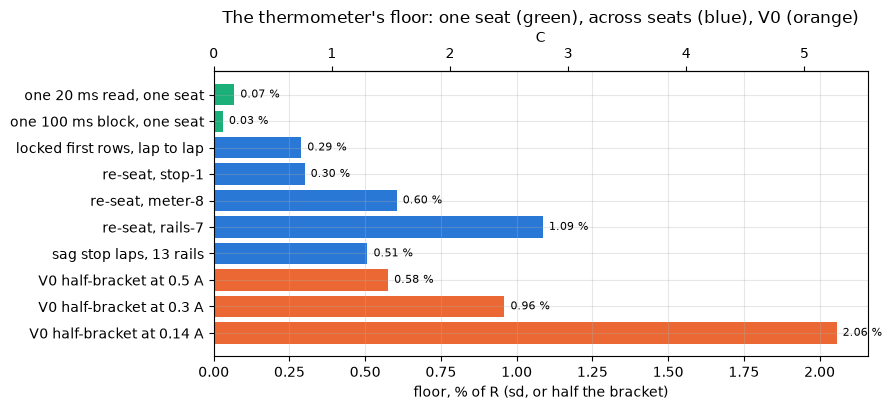

In [20]:
bars = [("one 20 ms read, one seat", FLOOR_SUB[0], GREEN),
        ("one 100 ms block, one seat", FLOOR_BLOCK, GREEN),
        ("locked first rows, lap to lap", 100 * REF[1] / REF[0], BLUE)]
bars += [(f"re-seat, {ds}", FLOOR_SEAT[ds][0], BLUE)
         for ds in ("stop-1", "meter-8", "rails-7")]
bars += [("sag stop laps, 13 rails", FLOOR_SAG, BLUE)]
bars += [(f"V0 half-bracket at {i} A", 100 * V0_HALF / (i * R0), ORANGE)
         for i in (0.5, 0.3, I_FLOOR)]
fig, ax = plt.subplots(figsize=(9, 4.2))
y = np.arange(len(bars))[::-1]
ax.barh(y, [b[1] for b in bars], color=[b[2] for b in bars])
ax.set_yticks(y, [b[0] for b in bars])
for yi, b in zip(y, bars):
    ax.text(b[1] + 0.02, yi, f"{b[1]:.2f} %", va="center", fontsize=8)
top = ax.secondary_xaxis("top", functions=(lambda p: p * C_PER_PCT,
                                           lambda c: c / C_PER_PCT))
top.set_xlabel("C")
figures.label(ax, x="floor, % of R (sd, or half the bracket)",
              title="The thermometer's floor: one seat (green), across "
              "seats (blue), V0 (orange)")
figures.finish(fig)

The thermometer has two floors. At one seat, one duty and one contact state it resolves 0.17 C in one 20 ms read and about 0.08 C in a block, with high confidence. Across seats, levels or sittings it resolves 0.30 to 1.09 % of R, 0.8 to 2.8 C, and that is the floor of every absolute reading here, with high confidence in the range. Which part of it is the commutator's angle and which the construction is not separated by this data. So the grade below keeps the two apart. Same-seat reads are graded as ratios, and reads across seats are named as such and carry that floor.

### The same-seat intercept

Where a chain steps the duty at one seat, the two levels give V0 with no other read. Each side's sub-windows are taken by their line to the step instant, so no heat falls between the two, and the line through the two levels at that instant crosses zero current at V0. A pair is kept when the seat moves at most 3 counts across the step, the duty changes by at least 2 %, and nothing unstreamed lies between the two sides.

In [21]:
pairs = []
for folder, g in G.groupby("folder", sort=False):
    segs = sorted(g["seg"].unique())
    for a, b in zip(segs[:-1], segs[1:]):
        ga, gb = g[g["seg"] == a], g[g["seg"] == b]
        if b != a + 1 or len(ga) < 3 or len(gb) < 3:
            continue                    # two adjacent windows of 3 reads
        if (abs(ga["duty_pct"].iloc[0] - gb["duty_pct"].iloc[0]) < 2
                or abs(ga["pos"].iloc[-1] - gb["pos"].iloc[0]) > 3):
            continue                    # a duty step at one seat
        t_step = gb["t"].iloc[0] - gb["t_in_seg"].iloc[0]
        if t_step - ga["t"].iloc[-1] > 0.08:
            continue                    # an unstreamed hold between
        ia, va = line_at(ga, t_step, "i_w_a"), line_at(ga, t_step, "v_c_v")
        ib, vb = line_at(gb, t_step, "i_w_a"), line_at(gb, t_step, "v_c_v")
        r = (va - vb) / (ia - ib)       # the line's R through both levels
        pairs.append({"folder": folder, "experiment": ga["experiment"].iloc[0],
                      "dataset": ga["dataset"].iloc[0],
                      "dir": ga["dir"].iloc[0], "i_a": ia, "i_b": ib,
                      "r_line": r, "v0_line": va - r * ia, "up": ib > ia})
STEP_PAIRS = pd.DataFrame(pairs)
STEP_PAIRS["kind"] = np.where(STEP_PAIRS["experiment"] == "load",
                              "load steps", STEP_PAIRS["dataset"])

In [22]:
V0_LINE = {}                            # kind: (mean, se, sd, n) in mV
for kind, g in STEP_PAIRS.groupby("kind", sort=False):
    v = g["v0_line"] * 1e3
    V0_LINE[kind] = results.wmean(v)
    m, s, se, n = V0_LINE[kind]
    print(f"{kind}: V0 {m:+.1f} +/- {se:.1f} mV (sd {s:.1f}, n {n}; up "
          f"{v[g['up']].mean():+.1f}, down {v[~g['up']].mean():+.1f}), "
          f"R of the line {g['r_line'].mean():.4f}")
ld = STEP_PAIRS[STEP_PAIRS["kind"] == "load steps"]
both = ld[ld[["i_a", "i_b"]].min(axis=1) >= I_FLOOR]  # both at the floor
V0_LOAD = results.wmean(both["v0_line"] * 1e3)
print(f"load steps, both levels at {I_FLOOR} A or more: V0 "
      f"{V0_LOAD[0]:+.1f} +/- {V0_LOAD[2]:.1f} mV (sd {V0_LOAD[1]:.1f}, n "
      f"{V0_LOAD[3]}), {(MOTOR.v0_v * 1e3 - V0_LOAD[0]) / V0_LOAD[2]:.1f} "
      f"se under stage 3's {MOTOR.v0_v * 1e3:+.1f}")

stop-1: V0 +29.5 +/- 1.9 mV (sd 6.7, n 12; up +29.9, down +29.1), R of the line 4.1940
rails-7: V0 +22.7 +/- 1.9 mV (sd 9.3, n 24; up +22.8, down +22.7), R of the line 4.2038
load steps: V0 +7.1 +/- 6.6 mV (sd 50.5, n 58; up -3.9, down +11.6), R of the line 4.3572
load steps, both levels at 0.14 A or more: V0 +12.6 +/- 5.8 mV (sd 42.1, n 52), 3.5 se under stage 3's +33.2


stop-1 gives +29.5 +/- 1.9 mV (n 12) and rails-7 +22.7 +/- 1.9 mV (n 24), both inside stage 3's bracket from the same data by a different reduction. The load's steps with both levels at the floor give +12.6 +/- 5.8 mV (sd 42.1, n 52), 3.5 of its own standard errors under +33.2 mV. The load's steps move the seat, and their sd is several times the stops', so it is carried as the alternative V0 for the load's reads in section 4 and not as a finding. The confidence that V0 differs under the arm is low.

### The bridged seats

Twelve blocks at the floor read well under R0 with a still pot and a quiet current.

In [23]:
br = over[over["r_ohm"] < BRIDGED * R0]
BRIDGED_HOLDS = br.groupby(["folder", "seg"]).agg(
    blocks=("r_ohm", "size"), i=("i_w_a", "mean"),
    duty=("duty_pct", "first"), r_lo=("r_ohm", "min"),
    r_hi=("r_ohm", "max"))
BRIDGED_HOLDS["ratio"] = BRIDGED_HOLDS["r_hi"] / R0
print(BRIDGED_HOLDS.round(3).to_string())
BRIDGED_RATIO = (br["r_ohm"].min() / R0, br["r_ohm"].max() / R0)
print(f"{len(br)} blocks in {br['folder'].nunique()} holds of "
      f"{READS['folder'].nunique()} sweeps with a read: R "
      f"{br['r_ohm'].min():.2f} to {br['r_ohm'].max():.2f} ohm, "
      f"{BRIDGED_RATIO[0]:.2f} to {BRIDGED_RATIO[1]:.2f} of R0, "
      f"{(1 - BRIDGED_RATIO[1]) * 100 * C_PER_PCT:.0f} to "
      f"{(1 - BRIDGED_RATIO[0]) * 100 * C_PER_PCT:.0f} C as a temperature")

                             blocks      i  duty   r_lo   r_hi  ratio
folder                  seg                                          
load/ladder-3/ladder/31 3         1  0.191  16.0  3.355  3.355  0.803
                        5         1  0.193  16.0  3.332  3.332  0.798
load/steps-2/chains/11  4         5  0.205  16.0  3.114  3.120  0.747
load/steps-2/chains/13  4         5  0.203  16.0  3.140  3.147  0.753
12 blocks in 3 holds of 246 sweeps with a read: R 3.11 to 3.35 ohm, 0.75 to 0.80 of R0, 50 to 65 C as a temperature


The bridged seats are load/steps-2 chains 11 and 13 at 16 % and load/ladder-3 rung 31. They read 0.75 to 0.80 of R0, close to the 3/4 a delta winding reads with one of its three coils shorted, which is what a brush touching two commutator segments does. They are left out of every fit below. For a stopped-rotor thermometer they are a hazard, since 20 to 25 % of R reads as 50 to 65 C. The confidence in the cause is moderate, since the ratio fits and nothing else checks it. The confidence in the rate is low, 3 holds of 246 sweeps with a read.

## 3. The heat history

The estimate needs the copper loss at every moment of every sitting, not only where a read is. `oscnb.winding.heat` builds it as pieces of $i_w^2$ against time over all of stage 3's sweeps, in time order, with a low and a high bound on each. The joules it reports are $i_w^2 R_0$. The estimate multiplies by $R(T_w)$ instead, which differs by under 10 % at the hottest hold.

There are three kinds of piece.

- Streamed rows. The winding current per row under the construction, squared, in 20 ms bins, and zero where the bridge sleeps or coasts.
- Unstreamed holds, the `hold` segments a sweep drives without streaming. The duty is known and the rotor is stopped, so the current is the stall current, which only falls as the copper warms. $i^2$ runs linearly from the streamed window before the hold to the one after, or is the one after's where the window before was not still.
- Seek presses. A stall sweep seeks the end stop at the seek duty and leaves the duty on until the first streamed row, so that releasing does not let the train unwind. The stream's opening rows still carry that current. The press's length is not recorded.

Between sweeps the bridge is off and the loss is zero. A free sweep's seek to its band and its brake are in no row either. They are bounded high at a free current and taken as zero.

### The assumptions for what no row streamed

The accounting rests on these constants at the top of `oscnb.winding`, each an assumption, not a measurement.

In [24]:
ASSUME = {name: getattr(wd, name) for name in (
    "HOLD_PIECE_S", "CHAIN_GAP_S", "FILL_MAX_S", "OPEN_ROWS",
    "POS_HEAD_ROWS", "SEEK_ROWS", "WATCH_S", "SEEK_MAX_S", "FREE_SEEK_A",
    "LIFT_S", "STALL_HEADROOM", "SEEK_DROP_V", "SEEK_MIN_REV_S")}
ASSUME["HEAD_ROWS"] = (wd.HEAD_ROWS.start, wd.HEAD_ROWS.stop)
for name, v in ASSUME.items():
    print(f"{name} = {v:g}" if np.isscalar(v) else f"{name} = {v}")

HOLD_PIECE_S = 0.1
CHAIN_GAP_S = 0.1
FILL_MAX_S = 0.05
OPEN_ROWS = 2
POS_HEAD_ROWS = 20
SEEK_ROWS = 200
WATCH_S = 0.16
SEEK_MAX_S = 1.5
FREE_SEEK_A = 0.15
LIFT_S = 0.5
STALL_HEADROOM = 1.1
SEEK_DROP_V = 0.45
SEEK_MIN_REV_S = 30
HEAD_ROWS = (40, 440)


- `STALL_HEADROOM` 1.1. Inside a hold the stall current is at most 10 % over the higher of the two windows around it, the copper being colder inside. The high bound of a hold is $1.1^2$ times the higher window's $i^2$.
- `LIFT_S` 0.5 s. A loaded lift comes to rest inside 0.5 s, so the low bound takes the window before's lower current for the first 0.5 s of a hold and the lower window's from there on.
- `HEAD_ROWS` 40 to 440. A window's opening current is read over rows 40 to 440, past the settle rows, and its closing current over its last 400 rows.
- `HOLD_PIECE_S` 0.1 s. A hold is cut into pieces of 0.1 s so the line in $i^2$ is followed.
- `CHAIN_GAP_S` 0.1 s. A drive that starts within 0.1 s of the one before is chained to it and has no seek of its own.
- `FILL_MAX_S` 0.05 s. Chained bursts are contiguous on the servo while the host stamps leave a few milliseconds between them, so a piece is stretched over a gap under 0.05 s and trimmed over an overlap.
- `OPEN_ROWS` 2. The seek press's current is the mean of the stream's first 2 rows.
- `WATCH_S` 0.16 s. A seek returns after 8 still polls of 20 ms, so a press lasts at least 0.16 s, the low bound.
- `SEEK_MAX_S` 1.5 s. After a rest the seek is the last part of the gap, at most 1.5 s of it, and the high bound is the press filling all of that.
- `SEEK_ROWS` 200 and `POS_HEAD_ROWS` 20. The pot the seek left is the mean of the last 200 rows before it and the pot it arrived at the mean of the stream's first 20, which give the travel.
- `SEEK_DROP_V` 0.45 V and `SEEK_MIN_REV_S` 30 rev/s. The seek travels at the seek duty's free speed, the duty's volts less 0.45 V over Ke, at least 30 rev/s. The central press is the gap less that travel.
- `FREE_SEEK_A` 0.15 A. A free sweep's seek to its band draws at most 0.15 A for the gap, an upper bound only.

In [25]:
PIECES, HEAT = wd.heat(PAIR_DIR, IX, BOARD, CHAIN, MOTOR, ZERO, POT_SCALE,
                       GEAR)            # every piece, joules per sweep
SITT = wd.heat_sittings(HEAT)           # joules per sitting
kind = PIECES["kind"]
hold = kind == wd.HOLD
prev_same = np.r_[False, hold[:-1] & (PIECES["sweep"][1:]
                                      == PIECES["sweep"][:-1])]
n_holds = int((hold & ~prev_same).sum())    # a run of hold pieces
J = HEAT[["j_stream", "j_hold", "j_hold_lo", "j_hold_hi", "j_seek",
          "j_seek_lo", "j_seek_hi", "j_free_seek_hi", "j_total"]].sum()
print(f"{len(HEAT)} sweeps, {len(kind)} pieces: "
      f"{int((kind == wd.STREAM).sum())} streamed, {int(hold.sum())} in "
      f"{n_holds} holds ({PIECES['dt'][hold].sum():.0f} s), "
      f"{int((kind == wd.SEEK).sum())} seek presses")
print(f"joules at R0: total {J['j_total']:.1f}, streamed "
      f"{J['j_stream']:.1f} ({100 * J['j_stream'] / J['j_total']:.0f} %), "
      f"holds {J['j_hold']:.1f} ({J['j_hold_lo']:.1f} to "
      f"{J['j_hold_hi']:.1f}), seeks {J['j_seek']:.1f} "
      f"({J['j_seek_lo']:.1f} to {J['j_seek_hi']:.1f})")
print(f"free seeks, upper bound only: {J['j_free_seek_hi']:.1f} J")

521 sweeps, 64077 pieces: 57411 streamed, 6600 in 217 holds (659 s), 66 seek presses
joules at R0: total 271.3, streamed 63.8 (24 %), holds 184.3 (161.8 to 225.4), seeks 23.3 (10.8 to 45.0)
free seeks, upper bound only: 67.6 J


In [26]:
un = J["j_hold"] + J["j_seek"]          # what no row streamed
un_lo = J["j_hold_lo"] + J["j_seek_lo"]
un_hi = J["j_hold_hi"] + J["j_seek_hi"]
SHARE = (100 * un / J["j_total"],
         100 * un_lo / (J["j_stream"] + un_lo),
         100 * un_hi / (J["j_stream"] + un_hi))
print(f"unstreamed share {SHARE[0]:.1f} % ({SHARE[1]:.1f} to "
      f"{SHARE[2]:.1f} at the bounds, free seeks out)")
print(f"a hold's joules at the bounds: "
      f"{100 * (J['j_hold_lo'] / J['j_hold'] - 1):+.0f} % and "
      f"{100 * (J['j_hold_hi'] / J['j_hold'] - 1):+.0f} % of the central")
sk = kind == wd.SEEK
press, i2s = PIECES["dt"][sk], PIECES["i2"][sk]
gap_seek = PIECES["hi"][sk] * press / i2s   # the gap the press may fill
SEEK = {"s": (np.median(press), press.min(), press.max()),
        "a": float(np.sqrt(np.median(i2s)))}
print(f"seek press {SEEK['s'][0]:.2f} s median ({SEEK['s'][1]:.2f} to "
      f"{SEEK['s'][2]:.2f}), {SEEK['a']:.3f} A median, "
      f"{SEEK['a'] ** 2 * R0:.2f} W, {np.median(i2s * press) * R0:.2f} J")
print(f"the gap it may fill: {gap_seek.min():.2f} to {gap_seek.max():.2f} s"
      f"; driven rows under the window floor: "
      f"{100 * HEAT['invalid_rows'].sum() / HEAT['driven_rows'].sum():.1f}"
      f" %")

unstreamed share 76.5 % (73.0 to 80.9 at the bounds, free seeks out)
a hold's joules at the bounds: -12 % and +22 % of the central
seek press 0.35 s median (0.16 to 0.43), 0.494 A median, 1.02 W, 0.37 J
the gap it may fill: 0.59 to 0.77 s; driven rows under the window floor: 9.0 %


In [27]:
tab = SITT[["day", "first", "sweeps", "dur_min", "j_stream", "j_hold",
             "j_hold_lo", "j_hold_hi", "j_seek", "j_seek_lo", "j_seek_hi",
             "j_total", "mean_w", "unstreamed_pct", "unstreamed_lo_pct",
             "unstreamed_hi_pct"]].copy()
tab["mean_mw"] = 1e3 * tab.pop("mean_w")  # mW reads better
print(tab.round(1).to_string())
live = SITT[SITT["j_total"] > 0]
print(f"mean power per sitting with a drive: {1e3 * live['mean_w'].min():.1f}"
      f" to {1e3 * live['mean_w'].max():.1f} mW")

                 day                   first  sweeps  dur_min  j_stream  j_hold  j_hold_lo  j_hold_hi  j_seek  j_seek_lo  j_seek_hi  j_total  unstreamed_pct  unstreamed_lo_pct  unstreamed_hi_pct  mean_mw
sitting                                                                                                                                                                                                    
1        11-06 03:15           servo-1-pilot     193    240.8      11.6     0.0        0.0        0.0     7.3        3.2       13.7     18.9            38.5               21.8               82.3      1.3
2        11-07 21:53                locked-4       6      6.2       8.0     0.0        0.0        0.0     0.0        0.0        0.0      8.0             0.0                0.0                0.0     21.3
3        11-07 22:11                 wound-5       2      1.7       0.1     4.6        3.4        7.0     0.0        0.0        0.0      4.7            97.8               97.1         

In [28]:
per = HEAT["j_total"]
largest = HEAT.loc[per.idxmax()]
print(f"per sweep: median {per.median():.2f} J, {int((per > 1).sum())} "
      f"over 1 J, the largest {per.max():.2f} J ({largest['folder']})")
free = HEAT.loc[HEAT["j_free_seek_hi"] > 0, "j_free_seek_hi"]
print(f"a free seek's upper bound: median {free.median():.2f} J a sweep")
DS = HEAT.groupby(["experiment", "dataset"], sort=False).agg(
    sweeps=("folder", "size"), j_median=("j_total", "median"),
    j_max=("j_total", "max"), j_sum=("j_total", "sum"))
print(DS.round(2).to_string())

per sweep: median 0.11 J, 101 over 1 J, the largest 5.11 J (load/ladder-1/ladder/22)
a free seek's upper bound: median 0.16 J a sweep
                                   sweeps  j_median  j_max  j_sum
experiment dataset                                               
sittings   servo-1-pilot                1      0.03   0.03   0.03
run-up     runup-open-1                 3      0.11   0.11   0.33
ladder     ref-open-1                   3      0.05   0.05   0.16
resistance stop-1                       6      0.65   0.69   3.93
ladder     capture-1                   45      0.05   0.10   2.25
           low-1                       51      0.04   0.07   2.25
steps      capture-1                   27      0.03   0.04   0.87
           reversal-1                   3      0.04   0.07   0.12
ladder     rail-1                       9      0.07   0.11   0.71
sag        capture-1                   39      0.04   0.59   7.81
ladder     ref-close-1                  3      0.05   0.05   0.13
run-up  

Of 271.3 J over the four days, 63.8 J (24 %) is in streamed rows, 184.3 J (161.8 to 225.4) in 217 unstreamed holds of 659 s in all, and 23.3 J (10.8 to 45.0) in 66 seek presses. A seek press lasts a median 0.35 s (0.16 to 0.43) at a median 0.494 A, 1.02 W. Per sweep the median is 0.11 J, 101 sweeps take over 1 J and the largest, load/ladder-1 rung 22 with two holds of 3 s, takes 5.11 J. A free seek's upper bound, which the totals leave out, is a median 0.16 J a sweep.

The figure gives the joules by sitting with what no row streamed, and that share with its bounds.

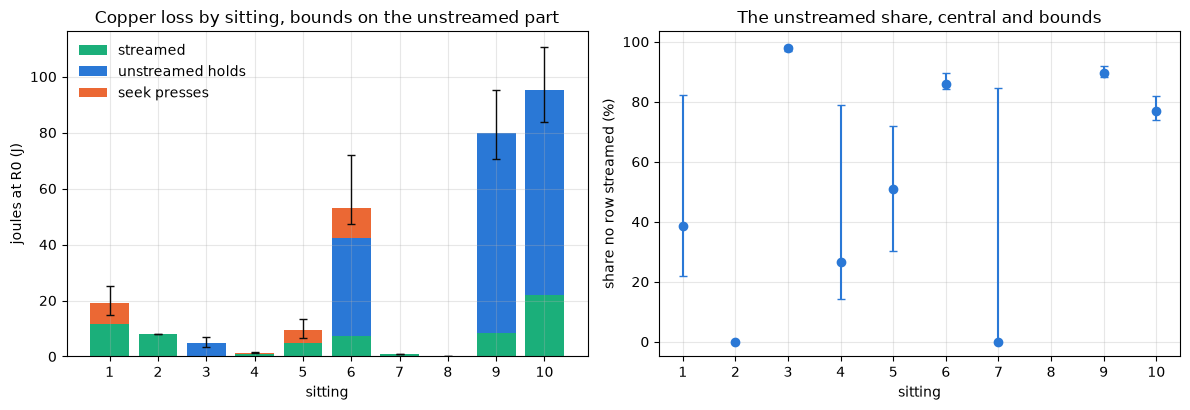

In [29]:
x = np.arange(len(SITT))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))
a1.bar(x, SITT["j_stream"], color=GREEN, label="streamed")
a1.bar(x, SITT["j_hold"], bottom=SITT["j_stream"], color=BLUE,
       label="unstreamed holds")
a1.bar(x, SITT["j_seek"], bottom=SITT["j_stream"] + SITT["j_hold"],
       color=ORANGE, label="seek presses")
lo = SITT["j_stream"] + SITT["j_hold_lo"] + SITT["j_seek_lo"]
hi = SITT["j_stream"] + SITT["j_hold_hi"] + SITT["j_seek_hi"]
a1.errorbar(x, SITT["j_total"], yerr=[SITT["j_total"] - lo,
                                      hi - SITT["j_total"]],
            fmt="none", ecolor=INK, capsize=3, lw=1)
a1.set_xticks(x, SITT.index)
a1.legend(frameon=False)
figures.label(a1, x="sitting", y="joules at R0 (J)",
              title="Copper loss by sitting, bounds on the unstreamed part")
a2.errorbar(x, SITT["unstreamed_pct"], yerr=[
    SITT["unstreamed_pct"] - SITT["unstreamed_lo_pct"],
    SITT["unstreamed_hi_pct"] - SITT["unstreamed_pct"]],
    fmt="o", color=BLUE, capsize=3)
a2.set_xticks(x, SITT.index)
figures.label(a2, x="sitting", y="share no row streamed (%)",
              title="The unstreamed share, central and bounds")
figures.finish(fig)

What you are looking at. On the left each bar is a sitting's joules, the streamed rows at the bottom, then the holds and the seek presses that no row streamed, with the whisker from the low to the high bound of the total. On the right the same sittings' unstreamed share. Sitting 8 is one hand-moved sweep with no drive. The high ends of sittings 1, 4 and 7 on the right are the free seeks' bound.

The unstreamed share is 76.5 % of the joules, 73.0 to 80.9 % at the bounds. It is bounded, not lost. A hold's current is pinned by the streamed window after it, to -12 % and +22 % of the central joules. The seek press is the loose one, a factor of 2 either way, and it is about as large as a stop chain's own streamed joules (sitting 5, 4.8 J of presses against 4.7 J streamed). So every stop read, stop-1, rails-7, the sag's stop laps and meter-8's first window, starts on copper the press has already warmed. 9.0 % of driven rows are under the window floor (`window_valid` 0), where the current reads low.

The mean power over a sitting is 0.9 to 45.1 mW. servo-7's sitting averages 5.9 mW and servo-meter-8's 30.3 mW, too little to drive the NTC's climb of section 2. No sitting held the winding warm. The heat arrives as isolated pulses of a few tenths of a joule to 5.11 J, a sweep's spacing apart, and the reads sit inside or right after a pulse.

## 4. The estimate

### Its form

The winding's temperature is the NTC plus a sum of heat nodes, each driven by the copper loss.

$$T_w = T_{ntc} + \sum_k x_k, \qquad x_k \leftarrow x_k + \left(G_k P - x_k\right)\left(1 - e^{-\Delta t / \tau_k}\right)$$

$$P = i_w^2 \, R(T_w), \qquad R(T) = R_0 \left(1 + \alpha (T - T_0)\right)$$

$T_w$ is the winding temperature, $T_{ntc}$ the board NTC, $x_k$ the rise of node $k$ over the NTC, $G_k$ its gain (C/W), $\tau_k$ (tau) its time constant (s) and $P$ the copper loss (W) over a step of length $\Delta t$. The nodes are in parallel (the Foster form), each a first-order rise toward $G_k P$. A node's heat capacity is $C_k = \tau_k / G_k$ (J/C), the joules it takes to warm it one degree.

The estimator keeps one float per node. It reads R0, T0, alpha, each node's gain and time constant, the NTC and the mean of $i_w^2$ over its step. The update is exact over a step of constant power, so it may run at any step, a control tick, a decimated block or a gap with no current. For a fixed step $e^{-\Delta t / \tau_k}$ is a constant.

Three candidates are graded. (a) The NTC alone, what stage 3's R(T) used. (b) The NTC plus one node, gain and time constant fitted. (c) Two nodes. Each is run down all of the heat history's pieces in time order from a zero state, causal, the gaps passing at zero current.

In [30]:
PT0, PDT = PIECES["t0"], PIECES["dt"]   # each piece's start and length, s
PI2 = {"central": PIECES["i2"], "low": PIECES["lo"], "high": PIECES["hi"]}
PNTC = wd.ntc_at(PT0, PROBES)           # the NTC at each piece, C
LISTS = {w: (PT0.tolist(), PDT.tolist(), PI2[w].tolist(), PNTC.tolist())
         for w in PI2}                  # the run's arguments, once
PEND = PT0 + PDT
live = PI2["central"] > 1e-4            # A^2, a piece with current
prev_end = np.r_[-1e18, PEND[:-1]]
new_run = live & ((PT0 - prev_end > wd.CHAIN_GAP_S)
                  | ~np.r_[False, live[:-1]])   # a drive starts
RUN_ID = np.cumsum(new_run)             # the drive each piece is in
RUN_START = pd.Series(PT0[new_run], index=RUN_ID[new_run])
last_live = pd.Series(np.where(live, PEND, np.nan)).ffill().shift(1)
RUN_REST = pd.Series((PT0 - last_live.to_numpy())[new_run],
                     index=RUN_ID[new_run])   # s of rest before a drive
run_len = (pd.Series(np.where(live, PEND, np.nan)).groupby(RUN_ID).max()
           - pd.Series(PT0).groupby(RUN_ID).min())
print(f"{len(PT0)} pieces, {int(new_run.sum())} drives; the longest "
      f"{', '.join(f'{v:.1f}' for v in run_len.nlargest(3))} s")

64077 pieces, 756 drives; the longest 36.3, 6.9, 6.8 s


### The residual and the split

At each block the residual is $\ln R_{read} - \ln R(T_w)$ in % of R, 1 % being 2.56 C, read two ways.

- Seat-referenced, less the weighted mean of its group. A group is one sweep, one direction and one duty, so one seat and one contact state. The load's single reads per hold have no partner at their seat, so they are grouped per load block and direction across seats, and carry the across-seat floor as their weight. That is a comparison across seats and is named so wherever it appears.
- As used, as it stands with stage 3's R0, T0 and V0.

A same-seat block weighs as 0.10 %, an across-seat block as 0.70 %, inside the 0.30 to 1.09 % floor of section 2. The fit sittings are 1, 6 and 9 (stop-1 and the sag's stop laps, meter-8, load-1). The held-out sittings are 2, 3, 5 and 10 (locked-4, held-5, rails-7, load-2 and load-3). The swap, fitted on the held-out sittings, and a fit on everything are reported for the constants' stability.

In [31]:
SIG_SEAT = 0.10         # %, a same-seat block about its group
SIG_ABS = 0.70          # %, a block across seats, inside section 2's floor
FIT_SITTINGS = (1, 6, 9)        # stop-1 and sag stops, meter-8, load-1
HELD_OUT = (2, 3, 5, 10)        # locked-4, held-5, rails-7, load-2 and 3


def blocks(v0_load=None):
    """The blocks at the floor, bridged seats out, grouped by seat, with
    their piece, time into the drive and rest before it; the load's R
    re-read at v0_load (V) when given."""
    B = BLK[BLK["i_w_a"] >= I_FLOOR].copy()
    if v0_load is not None:
        ld = B["experiment"] == "load"
        B.loc[ld, "r_ohm"] = ((B.loc[ld, "v_c_v"] - v0_load)
                              / B.loc[ld, "i_w_a"])
    B = B[B["r_ohm"] >= BRIDGED * R0].copy()
    B["duty_r"] = B["duty_pct"].round(0)
    B["group"] = (B["folder"] + "|" + B["dir"].astype(str) + "|"
                  + B["duty_r"].astype(str))    # one seat and duty
    by = B.groupby("group")
    nseg = by["seg"].transform("nunique")
    pspan = by["pos"].transform(lambda x: x.max() - x.min())
    B["same_seat"] = ~((B["experiment"] == "load")
                       & ((nseg < 2) | (pspan > 3)))
    across = ("load|" + B["dataset"].str.split("-").str[-1] + "|"
              + B["dir"].astype(str))   # load block and direction
    B.loc[~B["same_seat"], "group"] = across[~B["same_seat"]]
    B["sigma"] = np.where(B["same_seat"], SIG_SEAT, SIG_ABS)
    j = np.clip(np.searchsorted(PT0, B["t"].to_numpy(), "right") - 1, 0,
                len(PT0) - 1)           # the piece each block sits in
    B["piece"] = j
    B["drive_s"] = B["t"].to_numpy() - RUN_START.reindex(
        RUN_ID[j]).to_numpy()
    B["rest_s"] = RUN_REST.reindex(RUN_ID[j]).to_numpy()
    return B.reset_index(drop=True)

In [32]:
def rise_at(params, t, which="central", runs=None):
    """The rise over the NTC at times t: gains params[0::2], taus
    params[1::2], run down every piece (or `runs`, a run done before),
    each node evaluated inside its piece and decayed past its end."""
    gains, taus = list(params[0::2]), list(params[1::2])
    t = np.asarray(t, float)
    if not gains:
        return np.zeros(len(t))         # (a), the NTC alone
    starts, power = runs or wd.run(*LISTS[which], gains, taus, R0, T0,
                                   ALPHA)
    j = np.clip(np.searchsorted(PT0, t, "right") - 1, 0, len(PT0) - 1)
    since = t - PT0[j]
    on = np.minimum(since, PDT[j])      # s under the piece's power
    off = np.maximum(since - PDT[j], 0.0)   # s after it at zero
    p = np.asarray(power)[j]
    out = np.zeros(len(t))
    for k, (g, tau) in enumerate(zip(gains, taus)):
        x0 = np.asarray(starts[k])[j]
        e = np.exp(-on / tau)
        out += (x0 * e + g * p * (1 - e)) * np.exp(-off / tau)
    return out


def resid(params, B, which="central"):
    """(as used, seat-referenced, rise) at the blocks, % of R and C."""
    dT = rise_at(params, B["t"].to_numpy(), which)
    r_hat = wd.r_of_t(B["ntc_c"].to_numpy() + dT, R0, T0, ALPHA)
    e = 100 * np.log(B["r_ohm"].to_numpy() / r_hat)
    wgt = 1 / B["sigma"].to_numpy() ** 2
    grp = B["group"].to_numpy()
    gm = (pd.Series(e * wgt).groupby(grp).transform("sum")
          / pd.Series(wgt).groupby(grp).transform("sum"))
    return e, e - gm.to_numpy(), dT

In [33]:
def fit(B, n_nodes, x0, which="central"):
    """Least squares on the seat-referenced residual over sigma, in log
    gains and taus. Returns (params, se in log units, chi2, dof)."""
    def f(lp):
        _, es, _ = resid(np.exp(lp), B, which)
        return es / B["sigma"].to_numpy()
    lo = np.log([0.5, 0.2, 0.5, 15.0][:2 * n_nodes])    # C/W, s
    hi = np.log([300.0, 60.0, 300.0, 3000.0][:2 * n_nodes])
    s = least_squares(f, np.log(x0), bounds=(lo, hi), x_scale=0.3,
                      diff_step=0.02)
    dof = max(len(B) - B["group"].nunique() - 2 * n_nodes, 1)
    chi2 = float((s.fun ** 2).sum())
    try:
        cov = np.linalg.inv(s.jac.T @ s.jac) * max(chi2 / dof, 1.0)
        se = np.sqrt(np.diag(cov))      # in log units, a factor
    except np.linalg.LinAlgError:
        se = np.full(2 * n_nodes, np.nan)
    return np.exp(s.x), se, chi2, dof


def rms(x):
    """Root mean square."""
    return float(np.sqrt((np.asarray(x, float) ** 2).mean()))

In [34]:
def score(B, cands, tag, by):
    """Each candidate's residuals grouped by `by`: n, groups, the
    seat-referenced and the as-used mean, sd and rms, % of R."""
    rows = []
    for name, (params, which) in cands.items():
        e, es, _ = resid(params, B, which)
        D = B.assign(e=e, es=es)
        for key, g in D.groupby(by, observed=True):
            key = key if isinstance(key, tuple) else (key,)
            rows.append({"split": tag, "cand": name, **dict(zip(by, key)),
                         "n": len(g), "groups": g["group"].nunique(),
                         "seat_mean_pct": g["es"].mean(),
                         "seat_sd_pct": sd(g["es"]),
                         "seat_rms_pct": rms(g["es"]),
                         "used_mean_pct": g["e"].mean(),
                         "used_sd_pct": sd(g["e"]),
                         "used_rms_pct": rms(g["e"])})
    return pd.DataFrame(rows)

In [35]:
B = blocks()
B["i_bin"] = pd.cut(B["i_w_a"], [0.14, 0.25, 0.35, 0.45, 0.60, 0.80],
                    right=False).astype(str)    # A
B["drive_bin"] = pd.cut(B["drive_s"], [0, 0.4, 1.2, 4.5, 9, 60],
                        right=False).astype(str)    # s into the drive
B["rest_bin"] = pd.cut(B["rest_s"].fillna(1e9), [0, 30, 70, 600, 1e12],
                       right=False).astype(str)     # s of rest before
B["kind"] = np.where(B["experiment"] == "load",
                     np.where(B["same_seat"], "load same seat",
                              "load across seats"), B["dataset"])
TR = B[B["sitting"].isin(FIT_SITTINGS)].reset_index(drop=True)
TE = B[B["sitting"].isin(HELD_OUT)].reset_index(drop=True)
print(f"{len(B)} blocks in {B['group'].nunique()} groups: "
      f"{int(B['same_seat'].sum())} same-seat, "
      f"{int((~B['same_seat']).sum())} across seats")
print(f"fit sittings {FIT_SITTINGS}: {len(TR)} blocks, "
      f"{TR['group'].nunique()} groups; held out {HELD_OUT}: {len(TE)}, "
      f"{TE['group'].nunique()}")

960 blocks in 116 groups: 467 same-seat, 493 across seats
fit sittings (1, 6, 9): 404 blocks, 67 groups; held out (2, 3, 5, 10): 556, 49


### Where the reads sit inside a drive

A drive here is a run of pieces with current and no pause over 0.1 s, so a hold and the windows around it are one drive.

In [36]:
ds = np.sort(B["drive_s"].unique())     # s into the drive, every block
gaps = np.diff(ds)
wide = np.flatnonzero(gaps > 0.5)       # spans of half a second or more
print("no read inside a drive between: " + "; ".join(
    f"{ds[i]:.1f} and {ds[i + 1]:.1f} s" for i in wide))
print(B.groupby("dataset", sort=False)["drive_s"].agg(
    ["size", "min", "max"]).round(2).T.to_string())
print(f"rest before the drive: median {B['rest_s'].median():.1f} s, "
      f"{(B['rest_s'] < 70).mean() * 100:.0f} % of blocks under 70 s")

no read inside a drive between: 4.0 and 4.9 s; 4.9 and 5.7 s; 6.1 and 6.7 s; 6.8 and 36.2 s
dataset  locked-4  stop-1  rails-7  meter-8  capture-1  held-5  ladder-1  steps-1  bottom-2  ladder-2  steps-2  bottom-3  ladder-3  steps-3
size        36.00   53.00   108.00   201.00      39.00    2.00     39.00    72.00      8.00    138.00    80.00     10.00     21.00   153.00
min          0.08    0.38     0.43     0.24       0.42    0.07      2.36     2.33      0.78      1.27     0.08      0.69      1.30     0.08
max          0.25    1.19     1.29     3.99       0.68   36.24      6.09     2.88      0.95      6.84     3.42      0.97      4.87     3.55
rest before the drive: median 48.8 s, 99 % of blocks under 70 s


### The fit

Each candidate is fitted on the fit sittings, then on the held-out sittings (the swap) and on everything. The factor after a constant is its statistical standard error as a factor, the fit's covariance scaled by chi2 per degree of freedom.

In [37]:
FITS = {}           # set: (one node, se, chi2, dof, two nodes, se, ...)
CHI2_NTC = {}       # set: chi2 of (a), the NTC alone
for tag, D in (("fit", TR), ("swap", TE), ("all", B)):
    p1, se1, c1, d1 = fit(D, 1, [20.0, 4.0])
    p2, se2, c2, d2 = fit(D, 2, [p1[0], p1[1], 15.0, 100.0])
    FITS[tag] = (p1, se1, c1, d1, p2, se2, c2, d2)
    _, es0, _ = resid([], D)
    CHI2_NTC[tag] = float(((es0 / D["sigma"]) ** 2).sum())
    print(f"[{tag}] NTC alone chi2 {CHI2_NTC[tag]:.0f}; one node "
          f"{p1[0]:.1f} C/W (x/ {np.exp(se1[0]):.3f}), {p1[1]:.2f} s "
          f"(x/ {np.exp(se1[1]):.3f}), C {p1[1] / p1[0]:.3f} J/C, chi2 "
          f"{c1:.0f} / {d1}")
    print(f"[{tag}] two nodes {p2[0]:.1f} C/W {p2[1]:.2f} s + "
          f"{p2[2]:.1f} C/W {p2[3]:.0f} s (x/ "
          f"{', '.join(f'{v:.2f}' for v in np.exp(se2))}), chi2 "
          f"{c2:.0f} / {d2}")
P1, P2 = FITS["fit"][0], FITS["fit"][4]     # the constants of record
RISE3 = {tag: f[0][0] * (1 - np.exp(-3.0 / f[0][1]))
         for tag, f in FITS.items()}    # C/W at 3 s, one node
print("one node's rise at 3 s per watt: " + ", ".join(
    f"{tag} {v:.1f} C/W" for tag, v in RISE3.items()))

[fit] NTC alone chi2 17397; one node 23.2 C/W (x/ 1.012), 2.38 s (x/ 1.044), C 0.102 J/C, chi2 736 / 335
[fit] two nodes 17.1 C/W 1.93 s + 260.2 C/W 256 s (x/ 1.06, 1.06, 1.31, 1.36), chi2 659 / 333


[swap] NTC alone chi2 4014; one node 14.3 C/W (x/ 1.050), 1.40 s (x/ 1.080), C 0.098 J/C, chi2 1474 / 505
[swap] two nodes 9.2 C/W 1.03 s + 161.5 C/W 127 s (x/ 1.06, 1.07, 1.10, 1.16), chi2 975 / 503


[all] NTC alone chi2 21411; one node 23.1 C/W (x/ 1.015), 2.70 s (x/ 1.039), C 0.117 J/C, chi2 2314 / 842
[all] two nodes 14.4 C/W 1.84 s + 147.7 C/W 107 s (x/ 1.05, 1.06, 1.10, 1.16), chi2 1868 / 840
one node's rise at 3 s per watt: fit 16.7 C/W, swap 12.6 C/W, all 15.5 C/W


| candidate | fit sittings | swap | all | chi2 / dof (fit) |
|---|---|---|---|---|
| (a) NTC alone | - | - | - | 17397 |
| (b) one node | 23.2 C/W (x/ 1.012), 2.38 s (x/ 1.044), C 0.102 J/C | 14.3 C/W, 1.40 s, C 0.098 | 23.1 C/W, 2.70 s, C 0.117 | 736 / 335 |
| (c) two nodes | 17.1 C/W 1.93 s + 260.2 C/W 256 s (slow pair x/ 1.31, 1.36) | 9.2 C/W 1.03 s + 161.5 C/W 127 s | 14.4 C/W 1.84 s + 147.7 C/W 107 s | 659 / 333 |

One node's rise at 3 s per watt is 16.7 C/W on the fit sittings, 12.6 on the swap and 15.5 on everything.

In [38]:
SENS = {}           # the one-node fit on the fit sittings, varied
for which in ("low", "high"):           # the unstreamed heat's bounds
    SENS[f"unstreamed {which}"] = fit(TR, 1, list(P1), which)[0]
BV = blocks(V0_LOAD[0] * 1e-3)          # the load re-read at its own V0
SENS["load V0 in situ"] = fit(
    BV[BV["sitting"].isin(FIT_SITTINGS)].reset_index(drop=True), 1,
    list(P1))[0]
SENS["same seat only"] = fit(TR[TR["same_seat"]].reset_index(drop=True),
                             1, list(P1))[0]
SENS["across seats only"] = fit(
    TR[~TR["same_seat"]].reset_index(drop=True), 1, list(P1))[0]
for name, q in SENS.items():
    print(f"one node, {name}: {q[0]:.1f} C/W, {q[1]:.2f} s, C "
          f"{q[1] / q[0]:.3f} J/C")

one node, unstreamed low: 19.2 C/W, 1.20 s, C 0.063 J/C
one node, unstreamed high: 23.9 C/W, 3.23 s, C 0.135 J/C
one node, load V0 in situ: 23.2 C/W, 2.60 s, C 0.112 J/C
one node, same seat only: 23.2 C/W, 2.51 s, C 0.108 J/C
one node, across seats only: 45.1 C/W, 5.12 s, C 0.114 J/C


With the unstreamed heat at its low bound one node gives 19.2 C/W, 1.20 s and C 0.063 J/C, and at its high bound 23.9 C/W, 3.23 s and C 0.135 J/C. The load re-read at its own V0 of +12.6 mV gives 23.2 C/W and 2.60 s, the same-seat blocks alone 23.2 C/W and 2.51 s, and the across-seat blocks alone 45.1 C/W and 5.12 s, C 0.114 J/C.

### What bounds tau

The gain is fitted with tau held at each of a ladder of values.

In [39]:
prof = []           # tau held, the gain fitted: what bounds tau
for tau in (1.5, 2.5, 4.0, 6.0, 10.0, 20.0, 50.0, 200.0):
    def f(lg, tau=tau):
        _, es, _ = resid([np.exp(lg[0]), tau], TR)
        return es / TR["sigma"].to_numpy()
    s = least_squares(f, [np.log(P1[0] * tau / P1[1])], diff_step=0.02)
    g = float(np.exp(s.x[0]))
    prof.append({"tau_s": tau, "gain": g, "c_j_per_c": tau / g,
                 "chi2": float((s.fun ** 2).sum())})
TAU_PROFILE = pd.DataFrame(prof)
print(TAU_PROFILE.round(3).to_string(index=False))

 tau_s    gain  c_j_per_c     chi2
   1.5  24.040      0.062 1213.964
   2.5  23.357      0.107  738.786
   4.0  26.428      0.151  917.328
   6.0  32.275      0.186 1126.860
  10.0  45.415      0.220 1346.911
  20.0  80.683      0.248 1507.732
  50.0 190.529      0.262 1503.347
 200.0 717.314      0.279 1596.517


The profile has a clear minimum, chi2 1214 at 1.5 s, 739 at 2.5 s, 917 at 4 s, 1347 at 10 s and 1503 to 1597 from 20 s up. The reads see the node turn over inside 3 s. An integrator alone, the long-tau end of the profile, does not fit.

### What the second node is

The slow node's time constant is held at each of a ladder of values and the other three are fitted, on the fit sittings and on everything.

In [40]:
prof2 = []          # tau2 held, the other three fitted: the slow node
for tag, D in (("fit", TR), ("all", B)):
    for tau2 in (15.0, 35.0, 60.0, 120.0, 263.0, 600.0, 2000.0):
        def f(lp, tau2=tau2, D=D):
            q = np.exp(lp)
            _, es, _ = resid([q[0], q[1], q[2], tau2], D)
            return es / D["sigma"].to_numpy()
        s = least_squares(f, np.log([15.0, 1.8, tau2 / 0.8]),
                          diff_step=0.02, x_scale=0.3)
        q = np.exp(s.x)
        prof2.append({"set": tag, "tau2_s": tau2, "gain1": q[0],
                      "tau1": q[1], "gain2": q[2],
                      "c2_j_per_c": tau2 / q[2],
                      "chi2": float((s.fun ** 2).sum())})
TAU2_PROFILE = pd.DataFrame(prof2)
print(TAU2_PROFILE.round(2).to_string(index=False))
RIDGE_S = (35.0, 263.0)     # s, the tau2 the fit sittings' ridge spans
ridge = TAU2_PROFILE[TAU2_PROFILE["tau2_s"].between(*RIDGE_S)]["c2_j_per_c"]
C2 = (ridge.median(), ridge.min(), ridge.max())  # J/C, both sets
print(f"slow node's heat capacity over tau2 {RIDGE_S[0]:g} to "
      f"{RIDGE_S[1]:g} s, both sets: {C2[0]:.2f} J/C ({C2[1]:.2f} to "
      f"{C2[2]:.2f})")

set  tau2_s  gain1  tau1  gain2  c2_j_per_c    chi2
fit    15.0  18.19  1.96  14.33        1.05  732.04
fit    35.0  15.95  1.73  46.75        0.75  712.90
fit    60.0  15.35  1.69  85.47        0.70  691.73
fit   120.0  16.03  1.80 149.72        0.80  669.60
fit   263.0  17.14  1.94 265.39        0.99  658.95
fit   600.0  20.40  2.19 267.14        2.25  704.68
fit  2000.0  23.15  2.37  26.60       75.18  735.41
all    15.0  11.18  1.44  34.67        0.43 2151.86
all    35.0  12.10  1.51  68.50        0.51 2005.31
all    60.0  12.78  1.61 105.29        0.57 1908.55
all   120.0  14.81  1.90 155.25        0.77 1869.81
all   263.0  17.61  2.26 207.43        1.27 1929.73
all   600.0  19.86  2.48 265.97        2.26 2074.06
all  2000.0  22.42  2.65 182.34       10.97 2275.32
slow node's heat capacity over tau2 35 to 263 s, both sets: 0.76 J/C (0.51 to 1.27)


Reading (b). What is stable is the heat capacity, tau over gain, 0.098 to 0.117 J/C across the fit, the swap and everything. The gain and tau move together with the fold, 23.2 C/W and 2.38 s against 14.3 C/W and 1.40 s, and with the seek press's assumed length (1.20 to 3.23 s at the heat's bounds). The rise at 3 s is steadier, 12.6 to 16.7 C/W. The across-seat reads alone ask for about twice the gain, 45.1 C/W, so the load ladder's top rungs rise more than the same-seat pairs predict. The candidate causes are a slower term, as in (c), a slope of V0 or of the construction across the load's currents, or a rise not linear in power. The data does not separate them.

Reading (c). The fast pair is (b)'s, a little smaller. The slow pair is a ridge. With tau2 held anywhere from 35 to 600 s the fit sittings' chi2 stays within 659 to 713, against 732 at 15 s and 735 at 2000 s, which is (b) again, and the gain follows tau2. Over 35 to 263 s the ridge holds tau2 over gain2 at 0.70 to 0.99 J/C on the fit sittings and 0.51 to 1.27 on everything, median 0.76, the heat capacity of whatever the copper warms next. At 600 s that ratio is 2.25 J/C, so the ridge's span is a choice the data does not make sharply. A plateau gain of 147.7 to 260.2 C/W is not a measurement. No read saw a plateau.

In [41]:
CANDS = {"a_ntc": ([], "central"), "b_one": (P1, "central"),
         "c_two": (P2, "central")}
SCORES = pd.concat(
    [score(TE, CANDS, "held_out", [by]) for by in
     ("kind", "i_bin", "drive_bin", "rest_bin", "sitting", "dir")]
    + [score(TE.assign(all="all"), CANDS, "held_out", ["all"]),
       score(TR.assign(all="all"), CANDS, "fit", ["all"]),
       score(TR, CANDS, "fit", ["kind"])], ignore_index=True)
SWAP = {"a_ntc": ([], "central"), "b_one": (FITS["swap"][0], "central"),
        "c_two": (FITS["swap"][4], "central")}  # fitted on the held out
SCORES = pd.concat([SCORES, score(TR.assign(all="all"), SWAP,
                                  "swap_scored_on_fit", ["all"]),
                    score(TR, SWAP, "swap_scored_on_fit", ["kind"])],
                   ignore_index=True)


def table(split, by, cols=("seat_rms_pct",)):
    """One row per value of `by`: n, groups and each column per
    candidate, a / b / c."""
    s = SCORES[(SCORES["split"] == split) & SCORES[by].notna()]
    t = s.pivot_table(index=by, columns="cand", values=list(cols),
                      sort=False)
    t.columns = [f"{c.split('_')[0]}_{c.split('_')[1]}:{k[0]}"
                 for c, k in t.columns]
    n = s[s["cand"] == "a_ntc"].set_index(by)[["n", "groups"]]
    return n.join(t)

In [42]:
print("held out, by kind (seat-referenced rms, % of R):")
print(table("held_out", "kind").round(2).to_string())
print("the same in C:")
print((table("held_out", "kind").iloc[:, 2:] * C_PER_PCT).round(1)
      .to_string())
print("\nheld out, all:")
print(table("held_out", "all", ("seat_rms_pct", "used_mean_pct",
                                "used_sd_pct")).round(2).to_string())
print("\nheld out, by current (seat-referenced mean and rms):")
print(table("held_out", "i_bin", ("seat_mean_pct", "seat_rms_pct"))
      .round(2).to_string())

held out, by kind (seat-referenced rms, % of R):
                     n  groups  seat_rms:a  seat_rms:b  seat_rms:c
kind                                                              
held-5               2       1        1.01        0.58        0.14
load across seats  394       4        1.52        1.25        1.19
load same seat      16       8        0.30        0.30        0.20
locked-4            36      12        0.60        0.16        0.16
rails-7            108      24        0.22        0.08        0.08
the same in C:
                   seat_rms:a  seat_rms:b  seat_rms:c
kind                                                 
held-5                    2.6         1.5         0.4
load across seats         3.9         3.2         3.0
load same seat            0.8         0.8         0.5
locked-4                  1.5         0.4         0.4
rails-7                   0.6         0.2         0.2

held out, all:
       n  groups  seat_rms:a  seat_rms:b  seat_rms:c  used_mean:a  used_m

Held out, one node takes rails-7 from 0.22 to 0.08 % and locked-4 from 0.60 to 0.16 %, from 0.6 to 0.2 C and from 1.5 to 0.4 C. Two nodes match it on both. The load's same-seat pairs go 0.30, 0.30 and 0.20 % for (a), (b) and (c), and held-5's one pair 1.01, 0.58 and 0.14 %. The load's reads across seats sit at 1.52, 1.25 and 1.19 %, at the seat floor for every candidate. Over all 556 held-out blocks the rms is 1.29, 1.06 and 1.00 %.

By current, the NTC alone leaves a mean that grows with the current, -0.85 % from 0.14 to 0.25 A up to +2.44 % from 0.45 to 0.60 A. One node holds the mean within -0.39 to +0.23 % and two nodes within -0.72 to +0.12 %. The locked laps, alone in their bin, are their own groups and sit at zero mean by construction.

In [43]:
print("held out, by time into the drive (rms):")
print(table("held_out", "drive_bin").round(2).to_string())
print("\nheld out, by rest before the drive (rms):")
print(table("held_out", "rest_bin").round(2).to_string())
print("\nheld out, by sitting (rms):")
print(table("held_out", "sitting").round(2).to_string())
print("\nthe swap, scored on the fit sittings (rms):")
print(table("swap_scored_on_fit", "all").round(2).to_string())

held out, by time into the drive (rms):
               n  groups  seat_rms:a  seat_rms:b  seat_rms:c
drive_bin                                                   
[0.0, 0.4)    49      17        1.38        0.35        0.30
[0.4, 1.2)   118      28        1.10        0.87        1.10
[1.2, 4.5)   380      24        1.35        1.17        1.04
[4.5, 9.0)     8       8        0.30        0.30        0.20
[9.0, 60.0)    1       1        1.01        0.58        0.14

held out, by rest before the drive (rms):
                            n  groups  seat_rms:a  seat_rms:b  seat_rms:c
rest_bin                                                                 
[0.0, 30.0)                36      10        1.87        0.47        0.60
[30.0, 70.0)              515      42        1.24        1.09        1.03
[600.0, 1000000000000.0)    5       2        1.73        0.39        0.56

held out, by sitting (rms):
           n  groups  seat_rms:a  seat_rms:b  seat_rms:c
sitting                           

By time into the drive, under 0.4 s (n 49) the rms is 1.38, 0.35 and 0.30 %, from 0.4 to 1.2 s (n 118) 1.10, 0.87 and 1.10, from 1.2 to 4.5 s (n 380) 1.35, 1.17 and 1.04, from 4.5 to 9 s (n 8) 0.30, 0.30 and 0.20, and the one block past 9 s 1.01, 0.58 and 0.14. By rest before the drive, 515 of the 556 blocks follow a rest of 30 to 70 s, so the rest is not really graded. By sitting the split repeats the kinds, 2 the locked laps, 3 held-5, 5 rails-7 and 10 the load.

As used, with stage 3's R0, T0 and V0 and nothing taken out, the held-out mean and sd are +0.53 % and 1.61 for (a), -1.46 % and 1.44 for (b), -2.96 % and 1.53 for (c). Each added node lowers the mean by about 1.5 % because the reference R0 was itself read on warmed copper, the first discrepancy of section 7. Until that is settled the as-used mean does not choose between the candidates. Its sd, 1.44 to 1.61 %, is the across-seat floor plus V0's lever.

The swap, constants from the held-out sittings scored on the fit sittings, gives 1.32, 0.62 and 0.48 % over 404 blocks.

In [44]:
SCORED = [B]            # each block with every candidate's residual
for name, (params, which) in CANDS.items():
    e, es, dT = resid(params, B, which)
    SCORED.append(pd.DataFrame({f"{name}_used_pct": e,
                                f"{name}_seat_pct": es,
                                f"{name}_rise_c": dT}))
BS = pd.concat(SCORED, axis=1)
BS["held_out"] = BS["sitting"].isin(HELD_OUT)
BS["dT_read_c"] = (wd.dtemp_of_r(BS["r_ohm"], R0, ALPHA) + T0
                   - BS["ntc_c"])       # the read's copper over the NTC
RUNS = {c: wd.run(*LISTS["central"], p[0::2], p[1::2], R0, T0, ALPHA)
        for c, (p, _) in CANDS.items() if len(p)}   # for the figure
print(f"{len(BS)} blocks scored, {int(BS['held_out'].sum())} held out")

960 blocks scored, 556 held out


### The reads against the estimates

The figure is the notebook's central one. Six drives, each a panel, with the reads as dots and each candidate's estimate as a line, all as the copper's temperature over the board NTC. A read's absolute level carries its seat, so each candidate's line is moved by one constant per panel, the mean of the reads less the line, and the figure shows the shape in time that the seat-referenced grade scores.

In [45]:
COL = {"a_ntc": GREEN, "b_one": BLUE, "c_two": ORANGE}
NAME = {"a_ntc": "(a) NTC alone", "b_one": "(b) NTC + one node",
        "c_two": "(c) NTC + two nodes"}
PANELS = [("resistance/locked-4/chains/4", 1,
           "locked lap, 100 %, 0.77 A (held out)"),
          ("resistance/stop-1/chains/0", None,
           "stop chain 24 / 36 / 24 %, after the seek press (fit)"),
          ("resistance/meter-8/holds/0", None,
           "meter hold, 0.24 A, unstreamed between (fit)"),
          ("resistance/meter-8/holds/6", None,
           "meter hold, 0.36 A, unstreamed between (fit)"),
          ("load/ladder-1/ladder/22", None,
           "load, 50 % then 46 %, held 3 s each (fit)"),
          ("sag/held-5/held", None,
           "locked hold, 36 s, one read pair (held out)")]


def drive_start(t_lo, seg):
    """The first piece of the drive the reads from t_lo sit in."""
    j0 = np.searchsorted(PT0, t_lo, "right") - 1
    while (j0 > 0 and PT0[j0] - (PT0[j0 - 1] + PDT[j0 - 1]) < 0.1
           and (seg is None or PT0[j0] > t_lo - 0.2)):
        j0 -= 1
    return PT0[j0]

resistance/locked-4/chains/4: 3 blocks at 0.76 A
resistance/stop-1/chains/0: 9 blocks at 0.28 A
resistance/meter-8/holds/0: 6 blocks at 0.24 A
resistance/meter-8/holds/6: 6 blocks at 0.36 A
load/ladder-1/ladder/22: 2 blocks at 0.45 A
sag/held-5/held: 2 blocks at 0.17 A


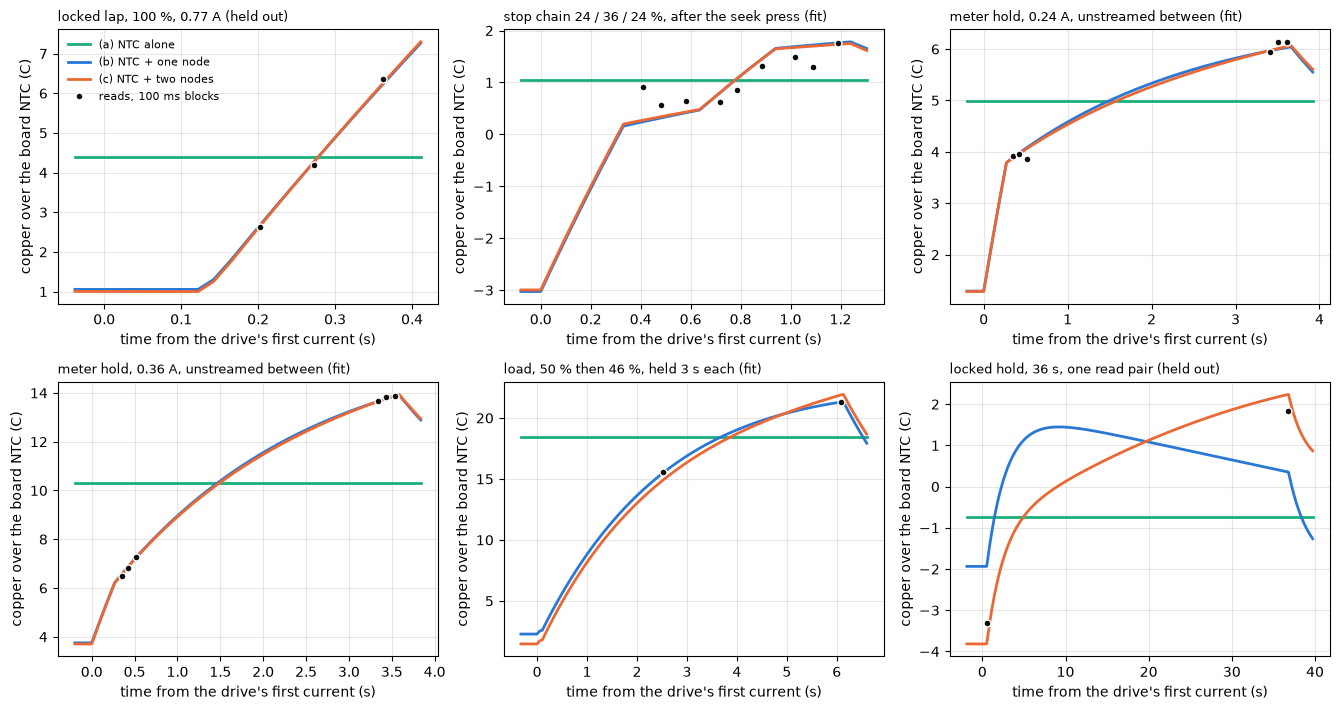

In [46]:
fig, axes = plt.subplots(2, 3, figsize=(13.5, 7.2))
for ax, (folder, seg, title) in zip(axes.ravel(), PANELS):
    g = BS[BS["folder"] == folder]
    g = g if seg is None else g[g["seg"] == seg]
    t_lo, t_hi = g["t"].min(), g["t"].max()
    t0 = drive_start(t_lo, seg)
    span = t_hi - t0
    grid = np.linspace(t0 - 0.05 * span - 0.02, t_hi + 0.08 * span + 0.02,
                       600)
    read = g["dT_read_c"].to_numpy()
    print(f"{folder}: {len(g)} blocks at {g['i_w_a'].mean():.2f} A")
    for c in COL:
        p = CANDS[c][0]
        at = rise_at(p, g["t"].to_numpy(), runs=RUNS.get(c))
        seat = float(np.mean(read - at))    # the seat's constant
        ax.plot(grid - t0, rise_at(p, grid, runs=RUNS.get(c)) + seat,
                color=COL[c], lw=2, label=NAME[c])
    ax.plot(g["t"] - t0, read, "o", ms=5, color=INK, mec="white",
            label="reads, 100 ms blocks")
    figures.label(ax, x="time from the drive's first current (s)",
                  y="copper over the board NTC (C)")
    ax.set_title(title, fontsize=9, loc="left")
axes[0, 0].legend(frameon=False, fontsize=8)
figures.finish(fig)

What you are looking at. Each panel is one drive, its time from the drive's first current, the press included. The dots are the reads' copper over the NTC, through R0, T0 and V0 of stage 3. The green line is the NTC alone, flat in time. The blue and orange lines are one and two nodes with the fit sittings' constants. On the stop chain and the meter holds the drive starts with the seek press, before the first read.

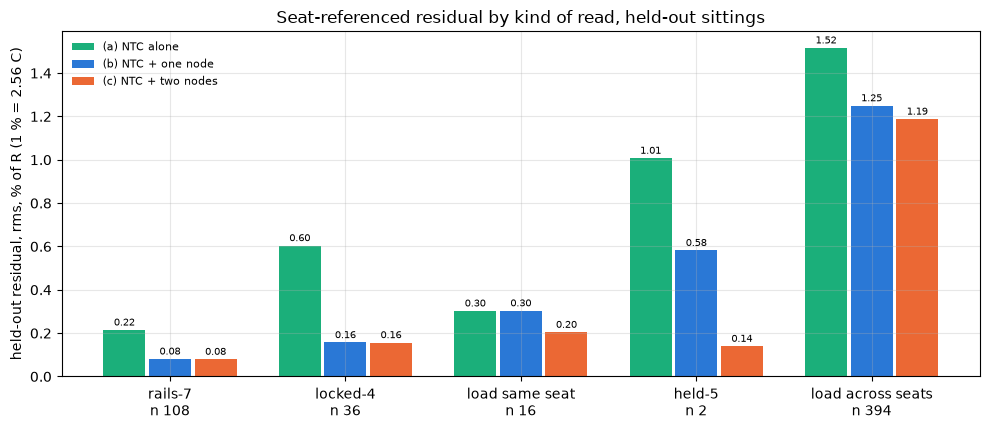

In [47]:
KINDS = ["rails-7", "locked-4", "load same seat", "held-5",
         "load across seats"]
H = SCORES[(SCORES["split"] == "held_out") & SCORES["kind"].notna()]
fig, ax = plt.subplots(figsize=(10, 4.4))
width = 0.26
for k, c in enumerate(COL):
    v = [float(H[(H["kind"] == kd) & (H["cand"] == c)]["seat_rms_pct"]
               .iloc[0]) for kd in KINDS]
    x = np.arange(len(KINDS)) + (k - 1) * width
    ax.bar(x, v, width * 0.92, color=COL[c], label=NAME[c])
    for xi, vi in zip(x, v):
        ax.text(xi, vi + 0.02, f"{vi:.2f}", ha="center", fontsize=7.5)
n = [int(H[(H["kind"] == kd) & (H["cand"] == "a_ntc")]["n"].iloc[0])
     for kd in KINDS]
ax.set_xticks(np.arange(len(KINDS)),
              [f"{kd}\nn {ni}" for kd, ni in zip(KINDS, n)])
ax.legend(frameon=False, fontsize=8)
figures.label(ax, y="held-out residual, rms, % of R (1 % = 2.56 C)",
              title="Seat-referenced residual by kind of read, held-out "
              "sittings")
figures.finish(fig)

What you are looking at. For each kind of held-out read, the rms of the seat-referenced residual for the three candidates, the number under each kind its blocks. The same-seat kinds are on the left, the load's reads across seats on the right.

### Two nodes, separated or not

Not to the standard of a finding. For a second node, the in-sample chi2 drops from 736 to 659 for two more parameters, from 1474 to 975 on the swap and from 2314 to 1868 on everything. The one 36 s hold goes from 0.58 to 0.14 %, the load's same-seat pairs from 0.30 to 0.20 %, and (b)'s constants move with the fold, which a missing slower term would do. Against it, held out overall it goes from 1.06 to 1.00 %, well inside the across-seat scatter, the same-seat kinds with the most data (rails-7, locked-4) are identical, held-5 is one event with the rail stepped inside it, and the slow node's gain and time constant are not pinned. The confidence that a slower term exists is moderate. Its heat capacity, 0.51 to 1.27 J/C, carries low confidence, and its gain and time constant are not graded.

### Is the 2 s term copper

A brush contact can also change its resistance over a second or two, and unlike copper's heat such a term may flip sign with the current. On mg90-d the term of that time scale is the main thing graded, so it is tested here, not assumed to be copper. Three checks, without any model first. The same-seat rise over a hold from its first window to its last, by level and by direction. The stop chains' first step, which a cold winding would see warm at $P / C$. And the model's rise at a chain's first block.

In [48]:
pr = []             # same-seat pairs: two windows of one hold, one seat
for folder, g in READS[READS["i_w_a"] >= I_FLOOR].groupby("folder",
                                                          sort=False):
    g = g.sort_values("seg")
    for a, b in zip(g.index[:-1], g.index[1:]):
        ra, rb = g.loc[a], g.loc[b]
        if (abs(ra["duty_pct"] - rb["duty_pct"]) > 0.5
                or abs(ra["pos"] - rb["pos"]) > 3 or rb["t"] - ra["t"] < 2.0):
            continue                    # one duty, one seat, a hold apart
        if ra["dir"] != rb["dir"] or not (
                ra["experiment"] == "load"
                or ra["dataset"] in ("meter-8", "held-5")):
            continue                    # the duty on between the two
        pr.append({"folder": folder, "dataset": ra["dataset"],
                   "experiment": ra["experiment"], "dir": ra["dir"],
                   "dt_s": rb["t"] - ra["t"], "t_a": ra["t"],
                   "t_b": rb["t"], "ntc_a": ra["ntc_c"],
                   "ntc_b": rb["ntc_c"],
                   "i_a": 0.5 * (ra["i_w_a"] + rb["i_w_a"]),
                   "p_w": 0.5 * (ra["i_w_a"] ** 2 * ra["r_ohm"]
                                 + rb["i_w_a"] ** 2 * rb["r_ohm"]),
                   "rise_pct": 100 * (rb["r_ohm"] / ra["r_ohm"] - 1)})
PAIRS = pd.DataFrame(pr)
PAIRS["lvl"] = np.where(
    PAIRS["experiment"] == "load", "load from-above",
    np.where(PAIRS["dataset"] == "held-5", "held-5",
             np.where(PAIRS["i_a"] > 0.3, "meter-8 high", "meter-8 low")))

In [49]:
PAIR_RISE = {}      # level: rise %, sd, n, W, s, fwd less rev, its se
for lvl, g in PAIRS.groupby("lvl", sort=False):
    f, r = g[g["dir"] > 0]["rise_pct"], g[g["dir"] < 0]["rise_pct"]
    split = f.mean() - r.mean() if len(f) and len(r) else np.nan
    se = (np.sqrt(sd(f) ** 2 / len(f) + sd(r) ** 2 / len(r))
          if len(f) > 1 and len(r) > 1 else np.nan)
    PAIR_RISE[lvl] = (g["rise_pct"].mean(), sd(g["rise_pct"]), len(g),
                      g["p_w"].mean(), g["dt_s"].mean(), split, se)
    print(f"{lvl}: rise {g['rise_pct'].mean():+.2f} % sd "
          f"{sd(g['rise_pct']):.2f} (n {len(g)}) over "
          f"{g['dt_s'].mean():.1f} s at {g['p_w'].mean():.2f} W; fwd less "
          f"rev {split:+.2f} +/- {se:.2f} %")
for c in ("b_one", "c_two"):            # the model's rise, same times
    p = CANDS[c][0]
    ra = wd.r_of_t(PAIRS["ntc_a"] + rise_at(p, PAIRS["t_a"],
                                            runs=RUNS[c]), R0, T0, ALPHA)
    rb = wd.r_of_t(PAIRS["ntc_b"] + rise_at(p, PAIRS["t_b"],
                                            runs=RUNS[c]), R0, T0, ALPHA)
    PAIRS[f"{c}_rise_pct"] = 100 * (rb / ra - 1)
print(PAIRS.groupby("lvl", sort=False)[["rise_pct", "b_one_rise_pct",
                                        "c_two_rise_pct"]].mean().round(2))
lo_, hi_ = PAIR_RISE["meter-8 low"], PAIR_RISE["meter-8 high"]
print(f"meter-8: {hi_[0] / lo_[0]:.1f} times the rise for "
      f"{hi_[3] / lo_[3]:.1f} times the power")

meter-8 low: rise +0.55 % sd 0.23 (n 18) over 3.1 s at 0.23 W; fwd less rev +0.16 +/- 0.10 %
meter-8 high: rise +2.49 % sd 0.19 (n 16) over 3.1 s at 0.55 W; fwd less rev -0.12 +/- 0.09 %
held-5: rise +2.14 % sd nan (n 1) over 36.2 s at 0.13 W; fwd less rev +nan +/- nan %
load from-above: rise +0.41 % sd 0.95 (n 15) over 3.4 s at 0.34 W; fwd less rev +0.27 +/- 0.51 %
                 rise_pct  b_one_rise_pct  c_two_rise_pct
lvl                                                      
meter-8 low          0.55            0.67            0.66
meter-8 high         2.49            2.44            2.41
held-5               2.14            0.96            2.43
load from-above      0.41            0.39            0.57
meter-8: 4.5 times the rise for 2.4 times the power


In [50]:
st = READS[READS["dataset"].isin(["stop-1", "rails-7"])
           & (READS["seg"] == 1)]       # each stop chain's first step
C_FIT = P1[1] / P1[0]                   # J/C, one node's heat capacity
C_HI = SENS["unstreamed high"][1] / SENS["unstreamed high"][0]
p_st = st["i_w_a"] ** 2 * st["r_ohm"]   # W in the first step
cold = 100 * ALPHA * p_st / C_FIT       # %/s a cold winding would rise
SLOPE1 = results.wmean(st["slope_pct_per_s"])
print(f"stop chains' first step, {p_st.mean():.2f} W: R slope "
      f"{SLOPE1[0]:+.2f} +/- {SLOPE1[2]:.2f} %/s (n {SLOPE1[3]}); cold "
      f"copper of {C_FIT:.3f} J/C would rise {cold.mean():+.2f} %/s, "
      f"{(100 * ALPHA * p_st / C_HI).mean():+.2f} at {C_HI:.3f} J/C, "
      f"{(cold.mean() - SLOPE1[0]) / SLOPE1[2]:.1f} se off")
for name, sl in (("3.3 V", SLOPE33), ("3.7 V", SLOPE37)):
    print(f"locked laps {name}: {sl[0]:.2f} sd {sl[1]:.2f} %/J, a heat "
          f"capacity of {100 * ALPHA / sl[0]:.3f} J/C")
PRESS_RISE = {}     # dataset: model rise at the first block, one, two
_, _, dT1 = resid(P1, B)
for d in ("stop-1", "rails-7", "capture-1"):
    m = (B["dataset"] == d) & (B["seg"] == 1) & (B["block"] == 0)
    two = rise_at(P2, B.loc[m, "t"].to_numpy(), runs=RUNS["c_two"])
    PRESS_RISE[d] = (float(dT1[m].mean()), float(two.mean()), int(m.sum()))
    print(f"model rise over the NTC at the first block of {d}: one node "
          f"{dT1[m].mean():.1f} C, two {two.mean():.1f} C (n {m.sum()}), "
          f"{dT1[m].mean() / C_PER_PCT:.1f} to "
          f"{two.mean() / C_PER_PCT:.1f} % of R")

stop chains' first step, 0.24 W: R slope -0.02 +/- 0.18 %/s (n 18); cold copper of 0.102 J/C would rise +0.91 %/s, +0.69 at 0.135 J/C, 5.2 se off
locked laps 3.3 V: 3.05 sd 0.14 %/J, a heat capacity of 0.128 J/C
locked laps 3.7 V: 4.53 sd 1.07 %/J, a heat capacity of 0.086 J/C
model rise over the NTC at the first block of stop-1: one node 3.2 C, two 4.5 C (n 6), 1.2 to 1.7 % of R
model rise over the NTC at the first block of rails-7: one node 3.7 C, two 5.7 C (n 12), 1.4 to 2.2 % of R
model rise over the NTC at the first block of capture-1: one node 3.8 C, two 4.3 C (n 13), 1.5 to 1.7 % of R


The direction. The same-seat rise over a meter-8 hold, forward less reverse, is +0.16 +/- 0.10 % at 0.23 W (n 18) and -0.12 +/- 0.09 % at 0.55 W (n 16). No term odd in the direction reaches 2 sigma.

The level. The rise is +0.55 % (sd 0.23) at 0.23 W and +2.49 % (sd 0.19) at 0.55 W over 3.1 s, 4.5 times the rise for 2.4 times the power. That looks non-thermal until the seek press is in the history. The low level starts above its own balance. With the press in the history one node gives +0.67 and +2.44 % over the same windows and two nodes +0.66 and +2.41 %, the ratio of the two levels reproduced to within the low level's scatter. The table above has the model's rise beside the read's for every level.

The initial slope. The heat capacity of the fit, 0.102 J/C, sits between the locked laps' own, 0.128 J/C from the 3.3 V laps' 3.05 sd 0.14 %/J and 0.086 J/C from the 3.7 V laps' 4.53 sd 1.07 %/J.

The stop chains' first step shows R flat, -0.02 +/- 0.18 %/s (n 18, 0.24 W), where a cold winding of 0.102 J/C would rise +0.91 %/s (+0.69 at 0.135 J/C), 5.2 standard errors off. The copper is already near its balance when the first row arrives, which is what a press of 0.35 s at 0.494 A does. One node puts the first block of a chain 3.2 to 3.8 C over the NTC, two nodes 4.3 to 5.7 C, 1.2 to 2.2 % of R.

The reading is copper warming over the rotor iron, with moderate confidence. The alternative is a contact film warming with $i^2$, with low confidence. It would behave the same in R, so the speed estimate does not care, but a thermal cutoff would then over-read the copper. This data does not separate the two.

## 5. What it costs the speed estimate

The back-EMF speed subtracts $R \, i_w$ from the volts, so an error in R reads as a speed error of $R \, i_w / K_e$ times the relative error ($K_e$ the back-EMF constant). The cost grows with the current. The load holds are where the current is high, but their single reads per hold sit across seats. Each block's residual is taken against the same load block's reads under 0.25 A, which share the NTC and the seat scatter but carry little heat, so what remains is the heating the candidate missed. That is a comparison across seats and carries the across-seat scatter.

In [51]:
KE = MOTOR.ke_v_per_rev_s                # V per rev/s
ld_all = BS[BS["kind"] == "load across seats"].copy()
for c in CANDS:
    low = ld_all[ld_all["i_w_a"] < 0.25].groupby("group")[f"{c}_used_pct"]
    ld_all[f"{c}_anch_pct"] = (ld_all[f"{c}_used_pct"]
                               - ld_all["group"].map(low.mean()))
rows = []
for (ho, b), g in ld_all.groupby(["held_out", "i_bin"]):
    per = wd.speed_error_rev_s(0.01, g["i_w_a"].mean(), R0, KE)
    rows.append({"held_out": ho, "i_bin": b, "n": len(g),
                 "i_a": g["i_w_a"].mean(), "rev_s_per_pct": per,
                 **{f"{c}_mean_pct": g[f"{c}_anch_pct"].mean()
                    for c in CANDS},
                 **{f"{c}_sd_pct": sd(g[f"{c}_anch_pct"]) for c in CANDS},
                 **{f"{c}_rms_rev_s": rms(g[f"{c}_anch_pct"]) * per
                    for c in CANDS}})
ANCH = pd.DataFrame(rows)
print("held out:")
print(ANCH[ANCH["held_out"]].drop(columns="held_out").round(2)
      .to_string(index=False))
print("fit sittings:")
print(ANCH[~ANCH["held_out"]].drop(columns="held_out").round(2)
      .to_string(index=False))

held out:
       i_bin   n  i_a  rev_s_per_pct  a_ntc_mean_pct  b_one_mean_pct  c_two_mean_pct  a_ntc_sd_pct  b_one_sd_pct  c_two_sd_pct  a_ntc_rms_rev_s  b_one_rms_rev_s  c_two_rms_rev_s
[0.14, 0.25) 176 0.18           1.00            0.00            0.00            0.00          1.08          1.17          1.20             1.08             1.17             1.20
[0.25, 0.35) 166 0.29           1.67            2.00            0.48           -0.24          0.81          1.40          1.33             3.61             2.46             2.26
[0.35, 0.45)  37 0.39           2.26            2.95            0.38           -0.81          0.99          0.73          0.76             7.02             1.84             2.50
 [0.45, 0.6)  15 0.48           2.77            3.86           -0.06           -0.79          0.79          1.19          0.79            10.93             3.19             3.05
fit sittings:
       i_bin  n  i_a  rev_s_per_pct  a_ntc_mean_pct  b_one_mean_pct  c_two_mean_pct  a

Per % of R the speed costs 1.00, 1.67, 2.26 and 2.77 rev/s at the load bins' mean currents of 0.18, 0.29, 0.39 and 0.48 A.

In [52]:
AH = ANCH[ANCH["held_out"]].reset_index(drop=True)
hot = AH[AH["i_bin"] != "[0.14, 0.25)"]     # the bins over the anchor
bias = hot["a_ntc_mean_pct"] * hot["rev_s_per_pct"]
print("NTC alone, mean bias in speed: " + ", ".join(
    f"{v:.1f}" for v in bias) + " rev/s at " + ", ".join(
    f"{i:.2f}" for i in hot["i_a"]) + " A")
for c in COL:                           # each mean over its se
    z = hot[f"{c}_mean_pct"] / (hot[f"{c}_sd_pct"] / np.sqrt(hot["n"]))
    print(f"{NAME[c]}, mean over its se: "
          + ", ".join(f"{v:+.1f}" for v in z))
AF = ANCH[~ANCH["held_out"]].set_index("i_bin")
top = AF.loc["[0.45, 0.6)"]             # the fit sitting's top rungs
print(f"fit sitting's top rungs: NTC alone {top['a_ntc_mean_pct']:+.2f} %"
      f" (sd {top['a_ntc_sd_pct']:.2f}, n {top['n']:.0f}), mean bias "
      f"{top['a_ntc_mean_pct'] * top['rev_s_per_pct']:.1f} rev/s")

NTC alone, mean bias in speed: 3.3, 6.7, 10.7 rev/s at 0.29, 0.39, 0.48 A
(a) NTC alone, mean over its se: +31.7, +18.1, +19.0
(b) NTC + one node, mean over its se: +4.4, +3.1, -0.2
(c) NTC + two nodes, mean over its se: -2.4, -6.5, -3.9
fit sitting's top rungs: NTC alone +6.15 % (sd 1.54, n 17), mean bias 16.7 rev/s


Held out, the NTC alone leaves a bias that grows with the current, +2.00, +2.95 and +3.86 % of R at 0.29, 0.39 and 0.48 A after a hold of 3 s, 3.3, 6.7 and 10.7 rev/s low in speed, each well over 2 standard errors. One node removes most of it, to -0.06 to +0.48 %, though the two lower bins are still 4.4 and 3.1 of their standard errors over zero. What remains is the across-seat scatter, sd 0.73 to 1.40 %, 1.84 to 3.19 rev/s rms, which no thermal model touches. Two nodes do not improve on one here. They over-correct by 0.24 to 0.81 %, within one sd of the blocks' scatter but 2.4 to 6.5 of their standard errors, so on these blocks two nodes read the load's heating high. In speed the rms goes from 3.61, 7.02 and 10.93 rev/s for the NTC alone to 2.46, 1.84 and 3.19 for one node and 2.26, 2.50 and 3.05 for two.

On the fit sitting's top rungs (load-1, 0.45 to 0.60 A) the NTC alone reads +6.15 % (sd 1.54, n 17) over the low rungs, a mean bias of 16.7 rev/s.

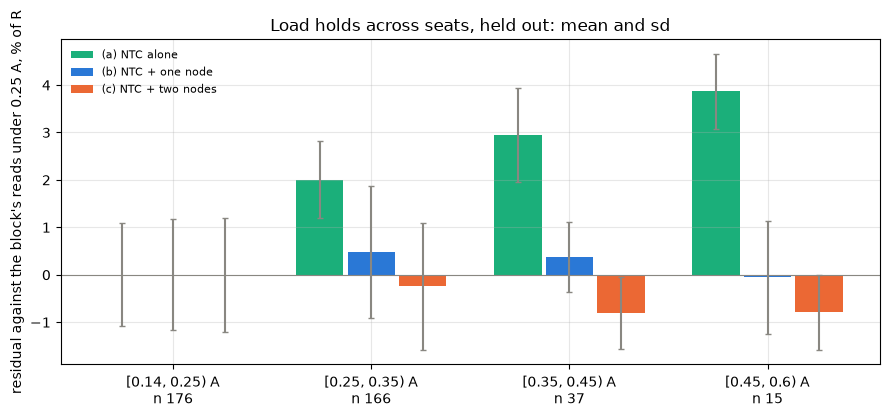

In [53]:
fig, ax = plt.subplots(figsize=(9, 4.2))
width = 0.26
for k, c in enumerate(COL):
    x = np.arange(len(AH)) + (k - 1) * width
    ax.bar(x, AH[f"{c}_mean_pct"], width * 0.92, color=COL[c],
           label=NAME[c])
    ax.errorbar(x, AH[f"{c}_mean_pct"], yerr=AH[f"{c}_sd_pct"], fmt="none",
                ecolor=MUTED, capsize=2)
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_xticks(np.arange(len(AH)), [f"{b} A\nn {n}" for b, n in
                                   zip(AH["i_bin"], AH["n"])])
ax.legend(frameon=False, fontsize=8)
figures.label(ax, y="residual against the block's reads under 0.25 A, "
              "% of R", title="Load holds across seats, held out: mean "
              "and sd")
figures.finish(fig)

What you are looking at. The load holds of the held-out sittings by current, each bar the mean residual of a candidate against the same load block's reads under 0.25 A, the whisker one sd. The first bin is the anchor itself and sits at zero by construction.

## 6. The verdict on the data

### What stage 3's sittings grade

- The copper's own heat capacity, 0.102 J/C, 0.098 to 0.117 by fold and 0.063 to 0.135 at the bounds of the unstreamed heat. It is graded from 60 ms to about a second at 0.24 to 2.4 W on same-seat reads, and held out to 0.08 to 0.16 % of R, 0.2 to 0.4 C. High confidence in the value's range.
- The first relaxation, the rise per watt at 3 s, 16.7 C/W (12.6 to 16.7), from one same-seat pair per meter hold at 0.23 and 0.55 W and across seats on the load. Moderate confidence.
- That the NTC alone reads low under load by 2.00 to 3.86 % of R after 3 s at 0.29 to 0.48 A, and that one node removes the bias. High confidence.

The data grades the first 3 s of a drive from a rested winding and nothing past that. The longest drive is 6.9 s, one other is 36.3 s, 99 % of the graded blocks follow a rest under 70 s, and the mean power of a sitting is at most 45.1 mW.

### What they do not grade, each gap with the capture that would close it

In [54]:
GAPS = [
    ("a plateau, the total gain winding to ambient",
     "the longest drive is 6.9 s, one of 36.3 s, mean power at most "
     "45.1 mW", "a stall hold on the horn lock at two currents (0.25 "
     "and 0.4 A) for 10 to 15 min each, a 100 ms window every 10 s"),
    ("the slower nodes (rotor iron, can)",
     "only the slow node's first seconds are seen, its heat capacity",
     "the same hold, then the cooling, a 100 ms probe pulse at low duty"
     " every 10 to 20 s for 15 min"),
    ("cooling at all", "no read at one seat after a rest, every sweep "
     "re-seats", "probe pulses after a hold with the seat kept (the "
     "lock, no seek, no move at torque off)"),
    ("a hot ambient", "the NTC is 24.5 to 28.7 C in every sitting",
     "a second ambient, on the printer bed or in a warm room"),
    ("the NTC against the can", "the NTC sits outside the case and "
     "climbs up to 2.18 C after power-up", "a thermocouple on the can, "
     "once, through a sitting"),
    ("the seek press", "its length is not recorded, 0.16 to 0.43 s",
     "stream the seek, or chains on the lock with no seek"),
    ("the reference under the construction", "the chains are read on "
     "warmed copper, the 100 % laps on cold", "partial-duty chains on "
     "the horn lock, static load, no seek, 60 s rests"),
    ("the bridged seats' rate", "3 holds in one sitting pair",
     "stopped reads at 20 or more rest angles a few counts apart"),
    ("between the windows of a hold", "holds are unstreamed between "
     "their windows", "stream the hold at a low rate, or holds of 1 "
     "and 2 s"),
]
lines = ["| gap | why the data does not grade it | the capture |",
         "|---|---|---|"] + [f"| {a} | {b} | {c} |" for a, b, c in GAPS]
display(Markdown("\n".join(lines)))

| gap | why the data does not grade it | the capture |
|---|---|---|
| a plateau, the total gain winding to ambient | the longest drive is 6.9 s, one of 36.3 s, mean power at most 45.1 mW | a stall hold on the horn lock at two currents (0.25 and 0.4 A) for 10 to 15 min each, a 100 ms window every 10 s |
| the slower nodes (rotor iron, can) | only the slow node's first seconds are seen, its heat capacity | the same hold, then the cooling, a 100 ms probe pulse at low duty every 10 to 20 s for 15 min |
| cooling at all | no read at one seat after a rest, every sweep re-seats | probe pulses after a hold with the seat kept (the lock, no seek, no move at torque off) |
| a hot ambient | the NTC is 24.5 to 28.7 C in every sitting | a second ambient, on the printer bed or in a warm room |
| the NTC against the can | the NTC sits outside the case and climbs up to 2.18 C after power-up | a thermocouple on the can, once, through a sitting |
| the seek press | its length is not recorded, 0.16 to 0.43 s | stream the seek, or chains on the lock with no seek |
| the reference under the construction | the chains are read on warmed copper, the 100 % laps on cold | partial-duty chains on the horn lock, static load, no seek, 60 s rests |
| the bridged seats' rate | 3 holds in one sitting pair | stopped reads at 20 or more rest angles a few counts apart |
| between the windows of a hold | holds are unstreamed between their windows | stream the hold at a low rate, or holds of 1 and 2 s |

No thermal capture is scheduled. The table names what would close each gap, nothing more.

### The bound a loop designer carries meanwhile

In [55]:
C_LO = SENS["unstreamed low"][1] / SENS["unstreamed low"][0]  # J/C
I_LIMIT = SEEK["a"]             # A, the seek duty is sized to the limit
P_LIMIT = I_LIMIT ** 2 * R0     # W at the current limit
ONE = [FITS[t][0] for t in FITS] + [SENS[k] for k in
                                    ("unstreamed low", "unstreamed high")]
gain_lim = [q[0] * P_LIMIT for q in ONE]    # the fast node's plateau, C
at5 = [q[0] * P_LIMIT * (1 - np.exp(-5.0 / q[1])) for q in ONE]
print(f"short pulses, every joule kept: {1 / C_LO:.1f} C/J at the low C "
      f"{C_LO:.3f} J/C, {1 / C_FIT:.1f} C/J at the value {C_FIT:.3f}")
print(f"the slow node's ceiling, no loss: {1 / C2[1]:.1f} C/J at C2 "
      f"{C2[1]:.2f} J/C")
across = SCORES[(SCORES["split"] == "held_out")
                & (SCORES["kind"] == "load across seats")
                & (SCORES["cand"] == "b_one")]["seat_rms_pct"].iloc[0]
print(f"across seats, one node: {across:.2f} % = "
      f"{across * C_PER_PCT:.1f} C rms")
print(f"at the current limit, {I_LIMIT:.3f} A and {P_LIMIT:.2f} W: the "
      f"fast node's own plateau {min(gain_lim):.1f} to "
      f"{max(gain_lim):.1f} C, its rise at 5 s {min(at5):.1f} to "
      f"{max(at5):.1f} C over the NTC")

short pulses, every joule kept: 16.0 C/J at the low C 0.063 J/C, 9.8 C/J at the value 0.102
the slow node's ceiling, no loss: 2.0 C/J at C2 0.51 J/C
across seats, one node: 1.25 % = 3.2 C rms
at the current limit, 0.494 A and 1.02 W: the fast node's own plateau 14.6 to 24.4 C, its rise at 5 s 14.2 to 20.8 C over the NTC


- For a drive of up to 3 s from a rested winding, $T_w = T_{ntc} + G_1 P (1 - e^{-t / \tau_1})$ with 23.2 C/W and 2.38 s, $P = i^2 R$. In R it holds within 0.48 % in the mean from 0.25 to 0.6 A held out, 1.25 % rms across seats and 0.08 to 0.30 % at one seat.
- A conservative ceiling for short pulses is every joule kept by the copper, 16.0 C/J at the low bound of the heat capacity (9.8 C/J at the value). It over-reads past about a second.
- Past 3 s one node under-reads by an amount this data does not size. A ceiling the data does support to 6.9 s, and once at 36.3 s, adds $E / C_2$ with $C_2$ the low end of the slow node's heat capacity and no loss, 2.0 C per joule since the drive began. Carried longer it only over-reads.
- The fast node's gain, 23.2 C/W (14.3 to 23.9), is a floor on mg90-d's plateau gain, not the plateau. At the current limit, 0.494 A and 1.02 W, the fast node alone puts the winding 14.6 to 24.4 C over the NTC once it settles, 14.2 to 20.8 C within 5 s, and the data says nothing about where the winding stops.
- On top of any of these sit 3.2 C rms across seats, the NTC's own climb of up to 2.18 C after power-up, and the open 3.2 to 5.7 C on the reference (the first discrepancy of section 7).

## 7. What stages 5 and 6 read from here

One table for the thermal side of the loops. Each row names what the data asks of a firmware, the state the estimator keeps, the constants it reads and the rate it may run at, and where its grade stops.

In [56]:
def hold_pct(params, i_a, hold_s, n=300):
    """R's rise in % after a hold of hold_s at i_a from the zero state,
    the estimator stepped n times at the NTC = T0."""
    x = wd.start_state(len(params) // 2)
    for _ in range(n):
        x, _ = wd.step(x, i_a ** 2, T0, hold_s / n, list(params[0::2]),
                       list(params[1::2]), R0, T0, ALPHA)
    t_w = wd.estimate(x, T0)
    return 100 * (wd.r_of_t(t_w, R0, T0, ALPHA) / R0 - 1)


HOLD_ONE = {t: hold_pct(FITS[t][0], 0.5, 3.0) for t in ("fit", "swap")}
HOLD_ONE_STEP = {t: hold_pct(FITS[t][0], 0.5, 3.0, n=1)
                 for t in ("fit", "swap")}    # one step at R0
print("in one step of 3 s: " + ", ".join(
    f"{t} {v:.1f} %" for t, v in HOLD_ONE_STEP.items()))
print(f"the fast node's four time constants: {4 * P1[1]:.1f} s")
print("one node at 0.5 A for 3 s: " + ", ".join(
    f"{t} {v:.1f} %" for t, v in HOLD_ONE.items()))
dv0 = MOTOR.v0_v - V0_LOAD[0] * 1e-3    # V, stage 3's V0 less the load's
lever = {i: 100 * dv0 / (i * R0) for i in (AH["i_a"].iloc[0],
                                           AH["i_a"].iloc[-1])}
print("V0 at +12.6 against stage 3's moves a read by " + ", ".join(
    f"{v:.1f} % at {i:.2f} A" for i, v in lever.items())
    + f", the rise between them by {np.ptp(list(lever.values())):.1f} %")

in one step of 3 s: fit 6.8 %, swap 5.1 %
the fast node's four time constants: 9.5 s
one node at 0.5 A for 3 s: fit 7.1 %, swap 5.4 %
V0 at +12.6 against stage 3's moves a read by 2.8 % at 0.18 A, 1.0 % at 0.48 A, the rise between them by 1.8 %


In [57]:
STAGE56 = [
    ("form", "T_w = T_ntc + x; x += (G P - x)(1 - exp(-dt / tau)); "
     "P = i_w^2 R(T_w); R(T) = R0 (1 + alpha (T - T0))",
     "one node; oscnb.winding step, run, estimate"),
    ("state", "one float per node, the rise over the NTC (C)",
     "zero after a power cycle"),
    ("constants", f"G {P1[0]:.1f} C/W ({min(q[0] for q in ONE):.1f} to "
     f"{max(q[0] for q in ONE):.1f}), tau {P1[1]:.2f} s "
     f"({min(q[1] for q in ONE):.2f} to {max(q[1] for q in ONE):.2f}), "
     f"C {C_FIT:.3f} J/C ({C_LO:.3f} to {C_HI:.3f})", "fit sittings 1, 6, 9"),
    ("reference", f"R0 {R0:.4f} ohm at T0 {T0:.2f} C, alpha "
     f"{100 * ALPHA:.2f} %/C", "R0 as a cold value open by 1.2 to 2.2 %"),
    ("rate", "any step: a control tick, a decimated block, a gap at zero "
     "current", "exact over a step of constant power"),
    ("error at one seat", "0.08 to 0.16 % of R rms (0.2 to 0.4 C), held "
     "out", "drives up to 3 s from a rest of about 45 s"),
    ("error across seats", f"{across:.2f} % rms ({across * C_PER_PCT:.1f}"
     " C), the seat floor", "load holds, held out"),
    ("bias under load", "within 0.48 % of R, against +2.00 to +3.86 % "
     "for the NTC alone", "0.29 to 0.48 A after 3 s"),
    ("speed", "1.84 to 3.19 rev/s rms at 0.3 to 0.5 A, against 3.61 to "
     "10.93 for the NTC alone", "held out, across seats"),
    ("second node, as a ceiling", f"C2 {C2[1]:.2f} J/C, tau2 at least "
     f"{RIDGE_S[0]:g} s", "its gain and tau not graded"),
]
lines = ["| quantity | value | note |", "|---|---|---|"]
lines += [f"| {a} | {b} | {c} |" for a, b, c in STAGE56]
display(Markdown("\n".join(lines)))

| quantity | value | note |
|---|---|---|
| form | T_w = T_ntc + x; x += (G P - x)(1 - exp(-dt / tau)); P = i_w^2 R(T_w); R(T) = R0 (1 + alpha (T - T0)) | one node; oscnb.winding step, run, estimate |
| state | one float per node, the rise over the NTC (C) | zero after a power cycle |
| constants | G 23.2 C/W (14.3 to 23.9), tau 2.38 s (1.20 to 3.23), C 0.102 J/C (0.063 to 0.135) | fit sittings 1, 6, 9 |
| reference | R0 4.1767 ohm at T0 26.26 C, alpha 0.39 %/C | R0 as a cold value open by 1.2 to 2.2 % |
| rate | any step: a control tick, a decimated block, a gap at zero current | exact over a step of constant power |
| error at one seat | 0.08 to 0.16 % of R rms (0.2 to 0.4 C), held out | drives up to 3 s from a rest of about 45 s |
| error across seats | 1.25 % rms (3.2 C), the seat floor | load holds, held out |
| bias under load | within 0.48 % of R, against +2.00 to +3.86 % for the NTC alone | 0.29 to 0.48 A after 3 s |
| speed | 1.84 to 3.19 rev/s rms at 0.3 to 0.5 A, against 3.61 to 10.93 for the NTC alone | held out, across seats |
| second node, as a ceiling | C2 0.51 J/C, tau2 at least 35 s | its gain and tau not graded |

Where it is not graded. Past 3 s, with one pair at 36.3 s where one node under-reads by 0.58 % and two nodes by 0.14 %, one event. Any plateau, any cooling, an ambient outside 24.5 to 28.7 C, a continuous duty cycle. A thermal derate or a cutoff built on this estimate has no graded basis past 3 s.

The start-up assumption after a power cycle is every node at zero, the winding at the NTC. The fast node is gone 9.5 s after the current stops, four of its time constants, so for it the assumption costs nothing after an off time of that length. Whatever slower heat the winding held is lost, and the estimate starts low by it. This data does not size that beyond the ceiling of 2.0 C per joule of the last drive. The NTC itself reads up to 2.18 C under its warmed-up value for the first half hour after power-up.

The hazards of a stopped-rotor read used as a live thermometer. The across-seat floor of 0.30 to 1.09 % of R, 0.8 to 2.8 C. A bridged commutator seat that reads 20 to 25 % low, 3 holds seen. V0's bracket, 2.1 % of R at 0.14 A.

### Open discrepancies and what would separate their causes

1. R0 at T0 is read on warmed copper. The stop chains' first step shows R flat, -0.02 +/- 0.18 %/s (n 18, 0.24 W), where cold copper of 0.102 J/C would rise +0.91 %/s, +0.69 at the high bound of the heat capacity, 5.2 standard errors off. The copper is near its balance when the first row arrives, which is what the press does, and the models put the first block 3.2 to 5.7 C over the NTC, 1.2 to 2.2 % of R. Stage 3's load intercept of 4.11 ohm (4.07 to 4.15) is 1.6 % under R0, consistent with that. But the locked 100 % laps' cold first row, 4.1796 ohm, agrees with R0 to 0.07 %. The readings are (i) the construction reads about 1.7 % under the 100 % read on cold copper and the press hid it (moderate), (ii) the press is at its short bound and the flat slope has another cause, a seat still settling (low), (iii) the 100 % laps are themselves high by the lock's creep (low). The separator is chains of 24, 36 and 24 % on the horn lock under a static load with no seek, after rests of 60 s, beside 100 % laps in the same seat. This notebook does not re-derive R0.
2. Stage 3's heat capacity bound of 0.077 J/C against the fitted 0.102. Stage 3's bound comes from the 3.7 V laps' slope, 4.96 %/J there and 4.53 sd 1.07 here, which stage 3's notes say carries the rotor's creep. The 3.3 V laps are several times tighter, 3.05 sd 0.14 %/J, and give 0.128 J/C. The readings are creep steepening the 3.7 V laps (moderate) or the 3.3 V rail's scale flattening those (low, since a scale error does not change a relative slope). The first discrepancy's locked chains separate them, giving the slope at 0.25 to 0.6 W with no creep.
3. Stage 3's meter hold tau of 3.39 s (3.08 to 3.74) against 2.38 s (1.20 to 3.23). Stage 3 fits one exponential to the hold from its first window, and here the press before the window is in the history. The two overlap only at this notebook's high bound. A meter hold with no press, on the lock, or a streamed seek separates them.
4. Load hold warming. Stage 3 has 9.99 % at 0.5 A for 3 s (low 4.82). One node gives 7.1 % at 0.5 A for 3 s stepped every 10 ms (5.4 % on the swap), 6.8 % in one step of 3 s at R0 (5.1 %). The fit sitting's top rungs read +6.15 % over the low rungs and the held-out ones +3.86 % at 0.48 A, both against the reads under 0.25 A. The spread is the across-seat comparison and V0, the load's +12.6 mV against +33.2 mV moving a read by 2.8 % of R at 0.18 A and 1.0 % at 0.48 A, so the ladder's rise between them by 1.8 %. Same-seat pairs at 0.5 A, a rung taken from above and streamed at both ends of one 3 s hold, separate them.
5. Two reads per load hold were expected. The start window is a lift, not a stall, and the pot shows it, so no experiment is needed.
6. V0 under the arm, +12.6 +/- 5.8 mV against +33.2 mV (+16.3 to +40.4). The readings are the seat moving at the step (moderate) or a real difference of the contact under a steady side load (low). Duty steps on the horn lock at the same currents separate them.
7. The slow node's fitted gain, 147.7 to 260.2 C/W, is not physical as a plateau. It is the ridge's arbitrary point. The long hold of the first gap separates it.

## Conclusion

On mg90-d the winding's temperature for a drive of up to 3 s from a rested winding is the board NTC plus one heat node driven by the copper loss, 23.2 C/W and 2.38 s, a heat capacity of 0.102 J/C. Held out at one seat it reads R to 0.08 % on the stop chains and 0.16 % on the locked laps, against 0.22 and 0.60 % for the NTC alone. Under the load the NTC alone reads R low by 2.00 to 3.86 % after 3 s at 0.29 to 0.48 A, 3.3 to 10.7 rev/s in the back-EMF speed, and one node removes that bias to within 0.48 %. What remains is the seat floor, about 1.2 % of R across seats, which no thermal model touches.

What is stable across the folds is the heat capacity. The gain and tau trade against each other with the fold and with the seek press's assumed length. A second, slower node is likely, at moderate confidence, but the data holds only its heat capacity, about 0.5 to 1.3 J/C, not its gain or tau. The data grades the first 3 s of a drive from a rest and nothing past that. No sitting held the winding warm, so there is no plateau, no cooling and no second ambient, and a thermal derate or cutoff built on this estimate has no graded basis past 3 s.

The result file. Every number in it is one servo on one board, mg90-d on dev-v006-2A-D, from stage 3's sittings of that pair.

In [58]:
q, pm = results.quantity, results.pm
RISE_Q = {**q(RISE["median"], RISE["lo"], RISE["hi"], "C"),
          "p05": RISE["p05"], "p95": RISE["p95"]}
REF_Q = {**pm(REF[0], REF[1], "ohm"), "sd": REF[1], "n": REF[3]}
seat_floor = [FLOOR_SEAT[d][0] for d in FLOOR_SEAT]
QUANTITIES = {
    "reads_n": q(int(OK.sum()), unit="sub-windows"),
    "read_windows_n": q(len(READS), unit="windows"),
    "read_sweeps_n": q(READS["folder"].nunique(), unit="sweeps"),
    "read_blocks_n": q(len(KEPT), unit="blocks"),
    "read_blocks_bridged_n": q(len(over) - len(KEPT), unit="blocks"),
    "read_current_floor_a": q(I_FLOOR, unit="A"),
    "rise_over_ref_c": RISE_Q,
    "ref_r0_ohm": q(R0, r0q["lo"], r0q["hi"], "ohm"),
    "ref_t0_c": q(T0, RES["board_ntc_c"]["lo"], RES["board_ntc_c"]["hi"],
                  "C"),
    "locked_first_row_r_ohm": REF_Q,
    "floor_same_seat_pct": q(*FLOOR_SUB[:3], "%"),
    "floor_same_seat_c": q(*(v * C_PER_PCT for v in FLOOR_SUB[:3]), "C"),
    "floor_block_pct": q(FLOOR_BLOCK, unit="%"),
    "floor_across_seats_pct": q(np.median(seat_floor), min(seat_floor),
                                max(seat_floor), "%"),
    "floor_across_seats_c": q(*(v * C_PER_PCT for v in (
        np.median(seat_floor), min(seat_floor), max(seat_floor))), "C"),
    "floor_across_seats_by_dataset_pct": {
        d: q(v[0], unit=f"%, {v[1]} groups, {v[2]} reads")
        for d, v in FLOOR_SEAT.items()},
    "floor_sag_stop_laps_pct": q(FLOOR_SAG, unit="%"),
}
print(len(QUANTITIES), "keys")

17 keys


In [59]:
QUANTITIES.update({
    "bridged_seat_ratio": q(np.mean(BRIDGED_RATIO), *BRIDGED_RATIO,
                            "of R0"),
    "bridged_seat_holds": q(br["folder"].nunique(), unit="holds"),
    "v0_same_seat_mv_stop_1": pm(V0_LINE["stop-1"][0],
                                 V0_LINE["stop-1"][2], "mV"),
    "v0_same_seat_mv_rails_7": pm(V0_LINE["rails-7"][0],
                                  V0_LINE["rails-7"][2], "mV"),
    "v0_same_seat_mv_load": pm(V0_LOAD[0], V0_LOAD[2], "mV"),
    "ntc_span_c": q(np.mean(NTC_SPAN), *NTC_SPAN, "C"),
    "ntc_self_heating_c": q(LONG_SIT["climb_c"].max(),
                            LONG_SIT["climb_c"].min(),
                            LONG_SIT["climb_c"].max(), "C"),
    "ntc_c_per_count": q(NTC_PER_COUNT, unit="C/count"),
    "heat_total_j": q(J["j_total"], unit="J"),
    "heat_streamed_j": q(J["j_stream"], unit="J"),
    "heat_hold_j": q(J["j_hold"], J["j_hold_lo"], J["j_hold_hi"], "J"),
    "heat_seek_j": q(J["j_seek"], J["j_seek_lo"], J["j_seek_hi"], "J"),
    "heat_free_seek_hi_j": q(J["j_free_seek_hi"], unit="J"),
    "heat_unstreamed_share_pct": q(*SHARE, "%"),
    "heat_by_sitting_j": {str(k): q(r["j_total"], unit="J")
                          for k, r in SITT.iterrows()},
    "mean_power_by_sitting_mw": {str(k): q(1e3 * r["mean_w"], unit="mW")
                                 for k, r in SITT.iterrows()},
    "seek_press_s": q(*SEEK["s"], "s"),
    "seek_press_a": q(SEEK["a"], unit="A"),
    "fit_sittings": list(FIT_SITTINGS),
    "held_out_sittings": list(HELD_OUT),
})
print(len(QUANTITIES), "keys")

37 keys


In [60]:
FOLD = {t: FITS[t][0] for t in FITS}    # the one node by fold


def over_folds(i, ratio=False):
    """One node's constant i (0 gain, 1 tau) or C over the folds and
    the heat's bounds: value (fit), lo, hi, fold lo, fold hi."""
    f = (lambda p: p[1] / p[0]) if ratio else (lambda p: p[i])
    fold = [f(p) for p in FOLD.values()]
    every = [f(p) for p in ONE]
    return f(P1), min(every), max(every), min(fold), max(fold)


def node_q(i, unit, ratio=False, se=None):
    v, lo, hi, flo, fhi = over_folds(i, ratio)
    out = {**q(v, lo, hi, unit), "fold_lo": flo, "fold_hi": fhi}
    if se is not None:
        out["stat_factor"] = float(np.exp(FITS["fit"][1][se]))
    return out


slow_tau = [FITS[t][4][3] for t in FITS]
QUANTITIES.update({
    "one_node_gain_c_per_w": node_q(0, "C/W", se=0),
    "one_node_tau_s": node_q(1, "s", se=1),
    "one_node_c_j_per_c": node_q(None, "J/C", ratio=True),
    "one_node_rise_at_3s_c_per_w": q(RISE3["fit"], min(RISE3.values()),
                                     max(RISE3.values()), "C/W"),
    "one_node_chi2": {t: {"chi2": FITS[t][2], "dof": FITS[t][3],
                          "chi2_ntc_alone": CHI2_NTC[t]} for t in FITS},
    "one_node_sensitivity": {k: {"gain_c_per_w": v[0], "tau_s": v[1],
                                 "c_j_per_c": v[1] / v[0]}
                             for k, v in SENS.items()},
})
print(len(QUANTITIES), "keys")

43 keys


In [61]:
two = [FITS[t][4] for t in FITS]
QUANTITIES.update({
    "two_node_fast_gain_c_per_w": q(P2[0], min(p[0] for p in two),
                                    max(p[0] for p in two), "C/W"),
    "two_node_fast_tau_s": q(P2[1], min(p[1] for p in two),
                             max(p[1] for p in two), "s"),
    "two_node_slow_c_j_per_c": q(*C2, "J/C"),
    "two_node_slow_tau_s_min": q(RIDGE_S[0], unit="s"),
    "two_node_slow_fitted": {t: {"gain_c_per_w": FITS[t][4][2],
                                 "tau_s": FITS[t][4][3]} for t in FITS},
    "two_node_chi2": {t: {"chi2": FITS[t][6], "dof": FITS[t][7]}
                      for t in FITS},
    "two_node_separated": False,
    "tau_profile": TAU_PROFILE.to_dict("records"),
    "tau2_profile": TAU2_PROFILE.to_dict("records"),
})
H_ALL = SCORES[(SCORES["split"] == "held_out") & SCORES["all"].notna()]
by_c = {c: g.iloc[0] for c, g in H_ALL.groupby("cand")}
QUANTITIES["heldout_rms_pct_all"] = {
    c: q(r["seat_rms_pct"], unit="%") for c, r in by_c.items()}
QUANTITIES["heldout_as_used_pct"] = {
    c: {**pm(r["used_mean_pct"], r["used_sd_pct"], "%"),
        "sd": r["used_sd_pct"]} for c, r in by_c.items()}
print(len(QUANTITIES), "keys")

54 keys


In [62]:
def by_axis(split, axis, col="seat_rms_pct"):
    """{axis value: {candidate: col, n}} from the scores."""
    s = SCORES[(SCORES["split"] == split) & SCORES[axis].notna()]
    return {str(k): {**{c: float(g[g["cand"] == c][col].iloc[0])
                        for c in COL}, "n": int(g["n"].iloc[0])}
            for k, g in s.groupby(axis, sort=False)}


QUANTITIES.update({
    "heldout_rms_pct_by_kind": by_axis("held_out", "kind"),
    "heldout_by_current_pct": {
        "mean": by_axis("held_out", "i_bin", "seat_mean_pct"),
        "rms": by_axis("held_out", "i_bin")},
    "heldout_rms_pct_by_drive_s": by_axis("held_out", "drive_bin"),
    "heldout_rms_pct_by_rest_s": by_axis("held_out", "rest_bin"),
    "swap_rms_pct_on_fit": by_axis("swap_scored_on_fit", "all"),
})
for lvl, key in (("meter-8 low", "low"), ("meter-8 high", "high")):
    r = PAIR_RISE[lvl]
    QUANTITIES[f"pair_rise_pct_meter_{key}"] = {
        **pm(r[0], r[1], "%"), "sd": r[1], "n": r[2], "p_w": r[3],
        "dt_s": r[4]}
QUANTITIES["pair_dir_split_pct"] = {
    k: pm(PAIR_RISE[f"meter-8 {k}"][5], PAIR_RISE[f"meter-8 {k}"][6], "%")
    for k in ("low", "high")}
print(len(QUANTITIES), "keys")

62 keys


In [63]:
spd = AH.set_index("i_bin")
QUANTITIES.update({
    "chain_first_step_slope_pct_per_s": {
        **pm(SLOPE1[0], SLOPE1[2], "%/s"), "n": SLOPE1[3],
        "cold_copper_would_be": float(cold.mean())},
    "press_rise_c": {d: {"one_node": v[0], "two_node": v[1], "n": v[2]}
                     for d, v in PRESS_RISE.items()},
    "speed_rev_s_per_pct_by_current": {
        b: q(r["rev_s_per_pct"], unit=f"rev/s per % at {r['i_a']:.3f} A")
        for b, r in spd.iterrows()},
    "speed_bias_ntc_alone_rev_s": {
        b: q(r["a_ntc_mean_pct"] * r["rev_s_per_pct"], unit="rev/s")
        for b, r in spd.iterrows() if b != "[0.14, 0.25)"},
    "speed_rms_rev_s_by_current": {
        b: {c: float(r[f"{c}_rms_rev_s"]) for c in COL}
        for b, r in spd.iterrows()},
    "load_anchored_mean_pct": {
        b: {c: pm(r[f"{c}_mean_pct"], r[f"{c}_sd_pct"], "%") for c in COL}
        for b, r in spd.iterrows()},
    "hold_pct_at_0p5a_3s_one_node": q(HOLD_ONE["fit"], HOLD_ONE["swap"],
                                      HOLD_ONE["fit"], "%"),
})
print(len(QUANTITIES), "keys")

69 keys


In [64]:
spans = [PAIR_RISE[k][4] for k in ("meter-8 low", "meter-8 high",
                                   "load from-above")]
QUANTITIES.update({
    "graded_drive_s_max": q(np.mean(spans[:2]), min(spans), max(spans),
                            "s, the same-seat pairs' span"),
    "longest_drive_s": q(run_len.max(), unit="s"),
    "plateau_graded": False,
    "can_node_graded": False,
    "ambient_graded": False,
    "stage56_table": [dict(quantity=a, value=b, note=c)
                      for a, b, c in STAGE56],
    "gaps": [dict(gap=a, why=b, capture=c) for a, b, c in GAPS],
})
print(len(QUANTITIES), "keys")

76 keys


In [65]:
NOTES = (
    "stage 4 winding-temperature of mg90-d on dev-v006-2A-D, no capture "
    "of its own: stage 3's sittings, 521 sweeps over four days. One servo"
    ", one board. Reads: 20 ms sub-windows of streamed driven segments of"
    " the stopped-rotor sweeps through oscnb.winding.gate, R = (V_c - V0)"
    " / i_w under oscnb.speed.construct with stage 1's in-drive offset; "
    "blocks of 100 ms at read_current_floor_a or more, bridged seats "
    "(under 0.9 of R0) out. Floors: same seat = a sub-window's sd about "
    "its window's line, median and 10 to 90 %; across seats = pooled sd "
    "of the first read of repeated stop, rail and duty chains, median "
    "and range over stop-1, rails-7, meter-8. Heat: oscnb.winding.heat, "
    "joules at R0, bounds from its named constants. Estimate: oscnb."
    "winding.run from a zero state over every piece; residual ln R - ln "
    "R(T_w), seat-referenced (group mean out, weights 0.10 % same seat, "
    "0.70 % across seats); fit sittings 1, 6, 9, held out 2, 3, 5, 10. "
)
NOTES += (
    "one_node_*: value the fit sittings, lo/hi over the fit, the swap, "
    "all and the unstreamed heat at its bounds, fold_lo/hi over the "
    "three fits, stat_factor the fit's se as a factor. two_node_slow_c: "
    "tau2 / gain2 over tau2 35 to 263 s on the fit sittings and on all, "
    "median and range; the slow gain and tau are not graded. load "
    "anchored: each load block's residual less its group's reads under "
    "0.25 A, across seats; speed = residual x R0 i / Ke. Candidates: "
    "a_ntc the NTC alone, b_one one node, c_two two nodes."
)
path = results.write(STAGE, EXPERIMENT, PAIR_DIR, pair=PAIR, notes=NOTES,
                     **QUANTITIES)
written = results.read(STAGE, EXPERIMENT, pair=PAIR)
print("wrote", path, "with", len(QUANTITIES), "keys, capture",
      written["capture"])

wrote stages/4-estimators/winding-temperature/results/mg90-d__dev-v006-2A-D.json with 76 keys, capture telemetry/mg90-d__dev-v006-2A-D


In [66]:
base = results.path(STAGE, EXPERIMENT, pair=PAIR)
READS_PATH = base.with_suffix(".reads.csv")
HEAT_PATH = base.with_suffix(".heat.csv")
READS.to_csv(READS_PATH, index=False, float_format="%.6f")
SITT.drop(columns="dur_min").assign(
    minutes=SITT["dur_min"], mean_mw=1e3 * SITT["mean_w"]).drop(
    columns="mean_w").to_csv(HEAT_PATH, float_format="%.4f")
for p in (READS_PATH, HEAT_PATH):
    back = pd.read_csv(p)
    print(f"wrote {results.rel(p)}: {len(back)} rows, columns "
          f"{', '.join(back.columns)}")

wrote stages/4-estimators/winding-temperature/results/mg90-d__dev-v006-2A-D.reads.csv: 426 rows, columns folder, experiment, dataset, sitting, seg, dir, fresh, n_sub, t, t_first, t_last, duty_pct, rail_v, v_on_v, i_w_a, i_sd_counts, pos, ntc_c, r_ohm, r_first, r_last, r_sub_sd_pct, slope_pct_per_s, dT_c


wrote stages/4-estimators/winding-temperature/results/mg90-d__dev-v006-2A-D.heat.csv: 10 rows, columns sitting, day, first, sweeps, j_stream, j_hold, j_hold_lo, j_hold_hi, j_seek, j_seek_lo, j_seek_hi, j_free_seek_hi, j_total, unstreamed_pct, unstreamed_lo_pct, unstreamed_hi_pct, minutes, mean_mw
